# Proyecto integrador — Fase 3: análisis predictivo
**Tema:** Factores asociados al desenlace registrado en las víctimas de accidentes de tránsito en Paraguay (2021).  
**Integrantes:** Alan Alcaraz, Leandro Ferreira y Jorge Rios.  
**Fuente oficial:** https://www.datos.gov.py/dataset/anuario-2021-estadisticas-policiales-y-de-accidentes-de-transito

## Alcance y diseño del experimento
**Objetivo:** comparar cuatro clasificadores de tres familias (regresión logística, árboles: árbol y bosque aleatorio, y Naive Bayes categórico) frente a una línea base, para clasificar el desenlace registrado (`es_fallecido`: 0 = herido, 1 = fallecido) en las frecuencias disponibles de la tabla 12.2.1.

**Advertencia esencial:** el archivo con 5.493 filas fue **expandido desde una tabla de frecuencias agrupadas** por `sexo`, `grupo_edad` y `gravedad`; no son microdatos individuales originales. El estudio dispone de **16 perfiles demográficos observables** (`sexo × grupo_edad`), no de 5.493 perfiles independientes con información adicional. La partición aleatoria estratificada sirve como **ejercicio académico de validación dentro de la distribución observada**, pero **no prueba generalización a siniestros, individuos, instituciones ni años nuevos**. Se complementa con una comprobación de sensibilidad dejando perfiles completos fuera del entrenamiento.

No disponemos de observaciones individuales que vinculen sexo, edad, zona geográfica y vehículo en una misma fila. Por ese motivo, el **modelo principal solo utiliza sexo y grupo de edad**. El contraste vehicular es **complementario y provisional**, pues la fuente 12.2.10 habla de víctimas de siniestros *protagonizados por motociclistas*, sin confirmar en estos archivos que cada víctima fuera ocupante de una motocicleta ni que su universo sea estrictamente comparable con 12.2.5.

**No es un modelo de prevención individual de accidentes ni una herramienta clínica.** Se evalúan asociaciones y capacidad de clasificación retrospectiva dentro de registros oficiales de 2021; no se establecen causas. La interpretación y las decisiones metodológicas deberán ser verificadas y defendidas por el grupo.

**Pregunta original:** ¿En qué medida la condición de usuario (motociclista frente a otros vehículos), el perfil demográfico (sexo y grupo etario) y la localización geográfica (Asunción, Central e Interior) se asocian con el desenlace fatal registrado en Paraguay durante 2021? Las cuatro hipótesis se discuten con evidencia de sus fuentes respectivas; el modelo principal se limita a sexo y grupo de edad; la evaluación territorial se realiza con conteos mensuales separados.

**Aclaraciones propias respecto de Fase 2 (sin devolución docente):** se mantiene la agrupación histórica de H1 y se explicita su efecto pequeño; H3 conserva el contraste anterior como condicionado a categorías vehiculares no acreditadas; H4 excluye los 353 desconocidos del contraste ordinal, recalcula U y efectos, y agrega el contraste de 60 años o más. Se preservan las entregas de Fases 1/2 y los resultados del modelo; las aclaraciones no son observaciones atribuidas al profesor.


## Lectura y continuidad con las fases anteriores
La Fase 1 preparó y describió las tablas; la Fase 2 estudió asociaciones. La Fase 3 examina una cuestión diferente: cuánto permite clasificar el desenlace observado utilizando solo sexo y edad. La pregunta inicial sobre motocicleta, perfil demográfico y geografía se responde de manera parcial porque las fuentes no vinculan esas dimensiones por persona.

**Tarea:** 0 = herido; 1 = fallecido. **Hipótesis operativa:** los predictores podrían mejorar F1 macro frente a la mayoría. Esto se comprobará, sin anticipar resultados favorables. Se sigue CRISP-DM: preparación, modelado, evaluación y comunicación.

Se verificará el origen de todas las frecuencias antes de modelar. La expansión facilita reproducir el experimento previo; no añade unidades independientes, fechas ni variables. La tabla agregada permite una representación alternativa por pesos, que se comprueba posteriormente.


In [1]:
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: División, Preprocesamiento y Modelos
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, GroupKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report, brier_score_loss
)

# Fijación de semilla para reproducibilidad matemática
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configuración de estilo gráfico
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 10.5,
    "axes.labelsize": 11.5,
    "axes.titlesize": 12.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
    "figure.titlesize": 13.5
})

def resolver_rutas():
    cwd = os.path.abspath(os.getcwd())
    candidatos_base = [cwd, os.path.abspath(os.path.join(cwd, "..")), os.path.abspath(os.path.join(cwd, "../.."))]
    ruta_base = next((c for c in candidatos_base if os.path.isdir(os.path.join(c, "output")) and os.path.isdir(os.path.join(c, "data"))), cwd)
    
    ruta_data = os.path.join(ruta_base, "data")
    ruta_output = os.path.join(ruta_base, "output")
    ruta_src = os.path.join(ruta_base, "src")
    
    os.makedirs(ruta_output, exist_ok=True)
    return ruta_base, ruta_data, ruta_output, ruta_src

BASE_DIR, DATA_DIR, OUTPUT_DIR, SRC_DIR = resolver_rutas()
print(f"[OK] Entorno configurado con semilla {RANDOM_STATE}")
print(f"     Directorio Base:   {BASE_DIR}")
print(f"     Directorio Output: {OUTPUT_DIR}")
from pathlib import Path
from sklearn.preprocessing import OrdinalEncoder, FunctionTransformer
from functools import partial
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import balanced_accuracy_score, make_scorer, average_precision_score
from sklearn.base import clone
from IPython.display import display, Markdown
sys.path.insert(0, BASE_DIR)
from src.preparar_datos import reconstruir
from src.complementos_fase3 import mostrar_complementos, publicar_resultados, preparar_contexto
_, auditoria_fuente = reconstruir(Path(BASE_DIR))
from src.regenerar_contexto import regenerar_resumenes
regenerar_resumenes(Path(BASE_DIR))
display(Markdown('La reconstrucción desde 12.2.1 preserva frecuencias y orden; los indicadores desconocidos ahora son NA. Se preservan 4.513 heridos, 980 fallecidos y 16 perfiles; el identificador solo numera la expansión.'))
from IPython import get_ipython
if get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('retina')


[OK] Entorno configurado con semilla 42
     Directorio Base:   C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience
     Directorio Output: C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\output


La reconstrucción desde 12.2.1 preserva frecuencias y orden; los indicadores desconocidos ahora son NA. Se preservan 4.513 heridos, 980 fallecidos y 16 perfiles; el identificador solo numera la expansión.

In [2]:
def cargar_csv_limpio(nombre_archivo):
    ruta = os.path.join(OUTPUT_DIR, nombre_archivo)
    if not os.path.exists(ruta):
        raise FileNotFoundError(ruta)

    for sep in [',', ';']:
        try:
            df = pd.read_csv(ruta, sep=sep, encoding='utf-8')
            if df.shape[1] > 1:
                df.columns = df.columns.astype(str).str.strip()
                return df
        except Exception:
            continue
    raise ValueError(f"Error al procesar el archivo: {ruta}")

df_demografico = cargar_csv_limpio("victimas_individual_limpio.csv")

print(f"Dataset Demográfico Nacional cargado: {df_demografico.shape[0]} filas, {df_demografico.shape[1]} columnas.")

assert df_demografico.shape[0] == 5493, "El dataset demográfico debe contener N = 5.493 observaciones."

# Auditoría de datos y su granularidad
assert set(df_demografico['es_fallecido'].unique()) == {0, 1}
assert set(df_demografico['sexo'].unique()) == {'Hombre', 'Mujer'}
assert df_demografico[['sexo', 'grupo_edad', 'es_fallecido']].isna().sum().sum() == 0
cantidad_perfiles = df_demografico[['sexo', 'grupo_edad']].drop_duplicates().shape[0]
print(f'Número de perfiles demográficos distintos: {cantidad_perfiles} (filas expandidas: {len(df_demografico)})')
print(f'Prevalencia observada de fallecimiento: {df_demografico.es_fallecido.mean():.4f}')

assert int(df_demografico.es_fallecido.sum()) == 980
assert (df_demografico.es_fallecido == df_demografico.gravedad.eq('Fallecido').astype(int)).all()
assert cantidad_perfiles == 16

Dataset Demográfico Nacional cargado: 5493 filas, 8 columnas.
Número de perfiles demográficos distintos: 16 (filas expandidas: 5493)
Prevalencia observada de fallecimiento: 0.1784


### 1. Preparación de datos y prevención de fuga de información
Solo se usan `sexo` y `grupo_edad`, codificados dentro del pipeline y ajustados dentro de cada pliegue. Se conservan las 5.493 frecuencias, incluidos 353 registros con edad desconocida como categoría nominal `Ignorado`.

Los indicadores derivados `es_adulto_mayor` y `edad_orden` tienen NA en esos 353 registros. Entre edades conocidas hay 4.832 menores de 60 y 308 de 60 años o más. El contraste ordinal corregido excluye desconocidos solo de ese análisis; no los elimina del dataset nacional. Los indicadores derivados no entran al clasificador.

La repetición de perfiles entre entrenamiento y prueba procede de la tabla agregada: la expansión no aporta información adicional ni acredita independencia por siniestro.

In [3]:
# 1. Selección de variables parsimoniosas (sin redundancia colineal)
X_demog = df_demografico[['sexo', 'grupo_edad']].copy()
y_demog = df_demografico['es_fallecido'].astype(int).values

# 2. Partición Estratificada 80/20
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_demog, y_demog,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_demog
)

# 3. Pipeline de preprocesamiento unificado
columnas_categoricas = ['sexo', 'grupo_edad']
preprocesador = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), columnas_categoricas)
    ],
    remainder='drop'
)

print(f"Distribución del target en Train (N = {len(y_train_d)}): {np.bincount(y_train_d)[1]} fallecidos ({np.mean(y_train_d)*100:.2f}%)")
print(f"Distribución del target en Test  (N = {len(y_test_d)}): {np.bincount(y_test_d)[1]} fallecidos ({np.mean(y_test_d)*100:.2f}%)")
assert not set(X_train_d.index) & set(X_test_d.index)
assert list(X_train_d.columns) == ['sexo', 'grupo_edad']

Distribución del target en Train (N = 4394): 784 fallecidos (17.84%)
Distribución del target en Test  (N = 1099): 196 fallecidos (17.83%)


### 2. Modelos, línea base y criterio de selección
Se conservan regresión logística, árbol y Random Forest, y se incorpora **Naive Bayes categórico**, familia generativa diferente. Dummy predice siempre herido. Los cuatro candidatos usan las mismas filas y cinco pliegues estratificados. La selección se fija por F1 macro CV, con desempate por el orden declarado; el recall fallecidos permite cuantificar omisiones.

Logística supone efectos aditivos en log-odds; árbol permite interacciones con poda; bosque promedia árboles para limitar varianza. Naive Bayes estima frecuencias condicionales de sexo y edad, suponiendo independencia entre ambos dado el desenlace. Ese supuesto puede fallar. Utiliza codificación ordinal solo como **índice de categoría**, sin imponer distancias, y suavizado de Laplace. El índice 0 se reserva para categorías no vistas en entrenamiento; se documenta el dominio de dos sexos y ocho edades de la fuente.

Los tres modelos originales conservan OneHotEncoder dentro del pipeline. No se escala: los indicadores son binarios, los árboles no necesitan escalas y Naive Bayes recibe índices nominales. Se conserva `class_weight='balanced'`; en Naive Bayes se fija prior 0,5/0,5 para una comparación con igual prioridad de clases. No se aplica sobremuestreo ni se ajusta un umbral usando test. Las puntuaciones de todos los modelos se consideran **no calibradas**.

Las grillas originales se conservan; para Naive Bayes se comparan alpha = 0,1; 1; 10. Las medias CV usadas para optimizar tienen sesgo de selección y no constituyen validación anidada independiente. Los desvíos entre pliegues no son intervalos de confianza poblacionales.


In [4]:
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Clasificador de referencia (Línea Base Trivial)
dummy_baseline = DummyClassifier(strategy='most_frequent')
dummy_baseline.fit(X_train_d, y_train_d)

configuraciones_modelos = {
    "Regresión Logística": {
        "pipeline": Pipeline([
            ('prep', preprocesador),
            ('clf', LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE, max_iter=1000))
        ]),
        "grid": {
            'clf__C': [0.01, 0.1, 1.0, 5.0, 10.0],
            'clf__solver': ['lbfgs']
        }
    },
    "Árbol de Decisión": {
        "pipeline": Pipeline([
            ('prep', preprocesador),
            ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE))
        ]),
        "grid": {
            'clf__max_depth': [2, 3, 4, 5, 6],
            'clf__min_samples_leaf': [10, 25, 50]
        }
    },
    "Random Forest": {
        "pipeline": Pipeline([
            ('prep', preprocesador),
            ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE))
        ]),
        "grid": {
            'clf__n_estimators': [50, 100, 150],
            'clf__max_depth': [3, 4, 5],
            'clf__min_samples_leaf': [10, 25]
        }
    }
}

configuraciones_modelos['Naive Bayes Categórico'] = {
    'pipeline': Pipeline([
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, dtype=np.int64)),
        ('reserva_desconocido', FunctionTransformer(partial(np.add, 1), feature_names_out='one-to-one')),
        ('clf', CategoricalNB(class_prior=[0.5, 0.5], min_categories=[3, 9]))
    ]),
    'grid': {'clf__alpha': [0.1, 1.0, 10.0]}
}
SCORING = {'f1_macro': make_scorer(f1_score, average='macro', zero_division=0),
           'accuracy': 'accuracy', 'precision': make_scorer(precision_score, zero_division=0),
           'recall': make_scorer(recall_score, zero_division=0),
           'f1': make_scorer(f1_score, zero_division=0), 'auc': 'roc_auc',
           'precision_herido': make_scorer(precision_score, pos_label=0, zero_division=0),
           'recall_herido': make_scorer(recall_score, pos_label=0, zero_division=0),
           'f1_herido': make_scorer(f1_score, pos_label=0, zero_division=0),
           'balanced_accuracy': 'balanced_accuracy',
           'brier': make_scorer(brier_score_loss, response_method='predict_proba')}
pliegues = list(cv_strat.split(X_train_d, y_train_d))
modelos_optimizados = {}
reporte_cv = []
resultados_busqueda = {}
grillas_cv = {}
cv_base = cross_validate(dummy_baseline, X_train_d, y_train_d, cv=pliegues,
                         scoring=SCORING, return_train_score=True, error_score='raise')
reporte_cv.append({'Modelo': 'Línea Base (Dummy)', 'Mejores Hiperparámetros': 'most_frequent',
                  'F1-Macro (Train CV)': cv_base['train_f1_macro'].mean(),
                  'F1-Macro (Validación CV)': cv_base['test_f1_macro'].mean(),
                  'Desvío CV': cv_base['test_f1_macro'].std(),
                  'Brecha Sobreajuste (CV)': (cv_base['train_f1_macro'] - cv_base['test_f1_macro']).mean()})
cv_metricas = [{'Modelo': 'Línea Base (Dummy)', 'metrica': k,
               'media_train': cv_base['train_' + k].mean(), 'media_validacion': cv_base['test_' + k].mean(),
               'desvio_validacion': cv_base['test_' + k].std()} for k in SCORING]
for nombre, cfg in configuraciones_modelos.items():
    busqueda = GridSearchCV(cfg['pipeline'], cfg['grid'], cv=pliegues, scoring=SCORING,
                           refit='f1_macro', return_train_score=True, n_jobs=1, error_score='raise')
    busqueda.fit(X_train_d, y_train_d)
    i = busqueda.best_index_
    resultados_busqueda[nombre] = busqueda.best_params_
    grillas_cv[nombre] = pd.DataFrame(busqueda.cv_results_)
    modelos_optimizados[nombre] = busqueda.best_estimator_
    tr, va = busqueda.cv_results_['mean_train_f1_macro'][i], busqueda.best_score_
    reporte_cv.append({'Modelo': nombre, 'Mejores Hiperparámetros': str(busqueda.best_params_),
                      'F1-Macro (Train CV)': tr, 'F1-Macro (Validación CV)': va,
                      'Desvío CV': busqueda.cv_results_['std_test_f1_macro'][i],
                      'Brecha Sobreajuste (CV)': tr - va})
    for k in SCORING:
        cv_metricas.append({'Modelo': nombre, 'metrica': k,
            'media_train': busqueda.cv_results_['mean_train_' + k][i],
            'media_validacion': busqueda.cv_results_['mean_test_' + k][i],
            'desvio_validacion': busqueda.cv_results_['std_test_' + k][i]})
df_reporte_cv = pd.DataFrame(reporte_cv).set_index('Modelo')
display(df_reporte_cv.round(4))
nombre_mejor_modelo = df_reporte_cv.loc[list(modelos_optimizados), 'F1-Macro (Validación CV)'].idxmax()
mejor_modelo_demografico = modelos_optimizados[nombre_mejor_modelo]
seleccion_cerrada = {'modelo': nombre_mejor_modelo, 'criterio': 'F1 macro CV train, antes de esta evaluación test',
                    'hiperparametros': resultados_busqueda, 'semilla': RANDOM_STATE,
                    'advertencia': 'La reserva ya fue inspeccionada en versiones anteriores; no es un holdout virgen.'}
display(Markdown(f"**Seleccionado por CV: {nombre_mejor_modelo}**, F1 macro = {df_reporte_cv.loc[nombre_mejor_modelo, 'F1-Macro (Validación CV)']:.4f}. La selección queda cerrada antes de calcular las métricas de prueba en esta ejecución."))
for nombre, tabla_grid in grillas_cv.items():
    display(Markdown(f'**Búsqueda en grilla: {nombre}.** Los puntajes siguientes utilizan únicamente los pliegues de entrenamiento; no el test.'))
    display(tabla_grid[['params', 'mean_train_f1_macro', 'mean_test_f1_macro', 'std_test_f1_macro', 'rank_test_f1_macro']].sort_values('rank_test_f1_macro'))
    mejor_fila = tabla_grid.sort_values('rank_test_f1_macro').iloc[0]
    display(Markdown(f"**Lectura de esta grilla:** la primera configuración por F1 macro CV es `{mejor_fila['params']}`, con media de validación {mejor_fila['mean_test_f1_macro']:.4f}, desvío {mejor_fila['std_test_f1_macro']:.4f} y media train {mejor_fila['mean_train_f1_macro']:.4f}. Son pliegues de train; el desvío no es un intervalo poblacional. Comparar estas medias optimizadas entre candidatos determina la selección, sin consultar test."))


,Mejores Hiperparámetros,F1-Macro (Train CV),F1-Macro (Validación CV),Desvío CV,Brecha Sobreajuste (CV)
Modelo,,,,,
Línea Base (Dummy),most_frequent,0.4510,0.4510,0.0001,-0.0000
Regresión Logística,"{'clf__C': 5.0, 'clf__solver': 'lbfgs'}",0.5330,0.5278,0.0169,0.0052
Árbol de Decisión,"{'clf__max_depth': 6, 'clf__min_samples_leaf':...",0.5444,0.5416,0.0106,0.0029
Random Forest,"{'clf__max_depth': 3, 'clf__min_samples_leaf':...",0.5235,0.5234,0.0133,0.0001
Naive Bayes Categórico,{'clf__alpha': 0.1},0.5374,0.5347,0.0137,0.0027


**Seleccionado por CV: Árbol de Decisión**, F1 macro = 0.5416. La selección queda cerrada antes de calcular las métricas de prueba en esta ejecución.

**Búsqueda en grilla: Regresión Logística.** Los puntajes siguientes utilizan únicamente los pliegues de entrenamiento; no el test.

,params,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro,rank_test_f1_macro
3,"{'clf__C': 5.0, 'clf__solver': 'lbfgs'}",0.533011,0.527779,0.016935,1
4,"{'clf__C': 10.0, 'clf__solver': 'lbfgs'}",0.533011,0.527779,0.016935,1
2,"{'clf__C': 1.0, 'clf__solver': 'lbfgs'}",0.530318,0.526297,0.017534,3
1,"{'clf__C': 0.1, 'clf__solver': 'lbfgs'}",0.525283,0.522823,0.013677,4
0,"{'clf__C': 0.01, 'clf__solver': 'lbfgs'}",0.522374,0.521295,0.012119,5


**Lectura de esta grilla:** la primera configuración por F1 macro CV es `{'clf__C': 5.0, 'clf__solver': 'lbfgs'}`, con media de validación 0.5278, desvío 0.0169 y media train 0.5330. Son pliegues de train; el desvío no es un intervalo poblacional. Comparar estas medias optimizadas entre candidatos determina la selección, sin consultar test.

...

,params,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro,rank_test_f1_macro
4,"{'clf__max_depth': 3, 'clf__min_samples_leaf':...",0.523474,0.523374,0.013315,1
14,"{'clf__max_depth': 5, 'clf__min_samples_leaf':...",0.525283,0.522823,0.013677,2
15,"{'clf__max_depth': 5, 'clf__min_samples_leaf':...",0.525283,0.522823,0.013677,2
16,"{'clf__max_depth': 5, 'clf__min_samples_leaf':...",0.525283,0.522823,0.013677,2
17,"{'clf__max_depth': 5, 'clf__min_samples_leaf':...",0.525283,0.522823,0.013677,2
7,"{'clf__max_depth': 4, 'clf__min_samples_leaf':...",0.522489,0.522459,0.011326,6
10,"{'clf__max_depth': 4, 'clf__min_samples_leaf':...",0.522489,0.522459,0.011326,6
6,"{'clf__max_depth': 4, 'clf__min_samples_leaf':...",0.521861,0.521729,0.011894,8
11,"{'clf__max_depth': 4, 'clf__min_samples_leaf':...",0.521861,0.521729,0.011894,8
9,"{'clf__max_depth': 4, 'clf__min_samples_leaf':...",0.521861,0.521729,0.011894,8


**Lectura de esta grilla:** la primera configuración por F1 macro CV es `{'clf__max_depth': 3, 'clf__min_samples_leaf': 25, 'clf__n_estimators': 100}`, con media de validación 0.5234, desvío 0.0133 y media train 0.5235. Son pliegues de train; el desvío no es un intervalo poblacional. Comparar estas medias optimizadas entre candidatos determina la selección, sin consultar test.

**Búsqueda en grilla: Naive Bayes Categórico.** Los puntajes siguientes utilizan únicamente los pliegues de entrenamiento; no el test.

,params,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro,rank_test_f1_macro
0,{'clf__alpha': 0.1},0.537381,0.534724,0.013672,1
1,{'clf__alpha': 1.0},0.537381,0.534724,0.013672,1
2,{'clf__alpha': 10.0},0.529736,0.526957,0.015492,3


**Lectura de esta grilla:** la primera configuración por F1 macro CV es `{'clf__alpha': 0.1}`, con media de validación 0.5347, desvío 0.0137 y media train 0.5374. Son pliegues de train; el desvío no es un intervalo poblacional. Comparar estas medias optimizadas entre candidatos determina la selección, sin consultar test.

### 3. Evaluación final y brecha de generalización
El modelo ganador se determina exclusivamente mediante F1-macro de validación cruzada. Una vez cerrados modelos e hiperparámetros, se calculan en la **única etapa final de evaluación** las métricas de todos los candidatos sobre las filas de prueba; **no se selecciona ni ajusta nada a partir de esos resultados**. Además se comparan entrenamiento, validación y prueba. La prueba aleatoria sigue estando limitada por los perfiles repetidos de la expansión.


**Historia del test:** la reserva se inspeccionó en versiones anteriores. Esta ejecución respeta un protocolo cerrado, pero no restaura su independencia histórica. Se necesita otra fuente o año para una evaluación externa. No hay fechas individuales en 12.2.1; no sería válido imponer una partición temporal al orden de expansión.

In [5]:
def evaluar_conjunto(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Fallecido)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (Fallecido)": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score (Fallecido)": f1_score(y_true, y_pred, zero_division=0),
        "F1-Macro": f1_score(y_true, y_pred, average='macro', zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Precision (Herido)": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1-Score (Herido)": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Specificity": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Brier": brier_score_loss(y_true, y_prob),
        "Average Precision": average_precision_score(y_true, y_prob)
    }

resultados_test = {}

# Línea Base
pred_dummy = dummy_baseline.predict(X_test_d)
resultados_test["Línea Base (Dummy)"] = evaluar_conjunto(y_test_d, pred_dummy, dummy_baseline.predict_proba(X_test_d)[:, 1])

# Modelos en Test
for nombre, modelo in modelos_optimizados.items():
    pred_te = modelo.predict(X_test_d)
    prob_te = modelo.predict_proba(X_test_d)[:, 1]
    resultados_test[nombre] = evaluar_conjunto(y_test_d, pred_te, prob_te)

df_resultados_test = pd.DataFrame(resultados_test).T

print("=" * 95)
print("TABLA 2: EVALUACIÓN FORMAL EN EL CONJUNTO DE RESERVA INTERNA HISTÓRICAMENTE INSPECCIONADA (N = 1.099)")
print("=" * 95)
display(df_resultados_test.round(4))

# Brecha final Train vs Test para el informe
tabla_brechas = []
for nombre, modelo in {'Línea Base (Dummy)': dummy_baseline, **modelos_optimizados}.items():
    f1_tr = f1_score(y_train_d, modelo.predict(X_train_d), average='macro', zero_division=0)
    f1_te = df_resultados_test.loc[nombre, "F1-Macro"]
    tabla_brechas.append({
        "Modelo": nombre,
        "F1-Macro (Train)": f1_tr,
        "F1-Macro (Test)": f1_te,
        "Brecha Absoluta": f1_tr - f1_te,
        "ROC-AUC (Test)": df_resultados_test.loc[nombre, "ROC-AUC"]
    })

df_brechas = pd.DataFrame(tabla_brechas).set_index("Modelo")
print("\n" + "=" * 95)
print("TABLA 2.B: AUDITORÍA DE GENERALIZACIÓN (ENTRENAMIENTO vs. PRUEBA)")
print("=" * 95)
display(df_brechas.round(4))
metricas_train = pd.DataFrame({nombre: evaluar_conjunto(y_train_d, m.predict(X_train_d), m.predict_proba(X_train_d)[:, 1])
    for nombre, m in {'Línea Base (Dummy)': dummy_baseline, **modelos_optimizados}.items()}).T

TABLA 2: EVALUACIÓN FORMAL EN EL CONJUNTO DE RESERVA INTERNA HISTÓRICAMENTE INSPECCIONADA (N = 1.099)


,Accuracy,Precision (Fallecido),Recall (Fallecido),F1-Score (Fallecido),F1-Macro,ROC-AUC,Precision (Herido),F1-Score (Herido),Specificity,Balanced Accuracy,Brier,Average Precision
Línea Base (Dummy),0.8217,0.0000,0.0000,0.0000,0.4510,0.5000,0.8217,0.9021,1.0000,0.5000,0.1783,0.1783
Regresión Logística,0.6069,0.2306,0.5153,0.3186,0.5212,0.5869,0.8563,0.7238,0.6268,0.5711,0.2445,0.2381
Árbol de Decisión,0.6351,0.2324,0.4541,0.3074,0.5299,0.5809,0.8506,0.7523,0.6744,0.5643,0.2457,0.2331
Random Forest,0.5723,0.2134,0.5204,0.3027,0.4971,0.5816,0.8486,0.6916,0.5836,0.5520,0.2447,0.2354
Naive Bayes Categórico,0.6069,0.2306,0.5153,0.3186,0.5212,0.5989,0.8563,0.7238,0.6268,0.5711,0.2445,0.2406



TABLA 2.B: AUDITORÍA DE GENERALIZACIÓN (ENTRENAMIENTO vs. PRUEBA)


,F1-Macro (Train),F1-Macro (Test),Brecha Absoluta,ROC-AUC (Test)
Modelo,,,,
Línea Base (Dummy),0.4510,0.4510,-0.0000,0.5000
Regresión Logística,0.5341,0.5212,0.0129,0.5869
Árbol de Decisión,0.5490,0.5299,0.0191,0.5809
Random Forest,0.5219,0.4971,0.0247,0.5816
Naive Bayes Categórico,0.5341,0.5212,0.0129,0.5989


### Interpretación de las métricas y la línea base
Dummy obtiene accuracy 0.8217, pero recall fallecidos 0.0000 y F1 macro 0.4510: predecir siempre herido oculta todas las fatalidades. El seleccionado por CV es Árbol de Decisión, con F1 macro CV 0.5416. En la misma reserva obtiene F1 macro 0.5299 (diferencia frente a Dummy +0.0788), recall 0.4541, precisión 0.2324 y AUC 0.5809. Otro candidato puede tener AUC mayor sin cambiar el criterio de selección previamente fijado.

El F1 macro train del seleccionado es 0.5490 y la brecha train-test es +0.0191. La tabla CV informa además train y validación por pliegue; el desvío no es un intervalo poblacional. La brecha pequeña puede reflejar perfiles compartidos y no garantiza ausencia de sobreajuste a la distribución agregada.

Precisión divide los verdaderos positivos por las predicciones positivas; recall divide por los fallecidos reales; F1 combina ambas y F1 macro pondera igual las dos clases. AUC mide ordenamiento, no calibración ni riesgo individual. Las matrices y curvas siguientes permiten evaluar los costos de error que una accuracy aislada ocultaría.


In [6]:
# Resumen reproducible (derivado directamente de las tablas anteriores)
sel = df_resultados_test.loc[nombre_mejor_modelo]
base = df_resultados_test.loc['Línea Base (Dummy)']
print(f"Seleccionado por validación cruzada: {nombre_mejor_modelo}")
print(f"F1-macro CV: {df_reporte_cv.loc[nombre_mejor_modelo, 'F1-Macro (Validación CV)']:.4f}")
print(f"En prueba: precisión fallecidos {sel['Precision (Fallecido)']:.4f}; recall fallecidos {sel['Recall (Fallecido)']:.4f}; F1 fallecidos {sel['F1-Score (Fallecido)']:.4f}; AUC-ROC {sel['ROC-AUC']:.4f}")
print(f"Línea base: precisión fallecidos {base['Precision (Fallecido)']:.4f}; recall fallecidos {base['Recall (Fallecido)']:.4f}; F1 fallecidos {base['F1-Score (Fallecido)']:.4f}; AUC-ROC {base['ROC-AUC']:.4f}")
print(f"Brecha F1-macro entrenamiento-prueba del ganador: {df_brechas.loc[nombre_mejor_modelo, 'Brecha Absoluta']:.4f}")

Seleccionado por validación cruzada: Árbol de Decisión
F1-macro CV: 0.5416
En prueba: precisión fallecidos 0.2324; recall fallecidos 0.4541; F1 fallecidos 0.3074; AUC-ROC 0.5809
Línea base: precisión fallecidos 0.0000; recall fallecidos 0.0000; F1 fallecidos 0.0000; AUC-ROC 0.5000
Brecha F1-macro entrenamiento-prueba del ganador: 0.0191


### 3.B. Sensibilidad: dejar perfiles completos fuera de la validación
La validación aleatoria utiliza filas expandidas; las mismas categorías de edad y sexo aparecen tanto en train como en validación. Como **análisis de sensibilidad**, dejamos fuera grupos definidos por la combinación completa (`sexo`, `grupo_edad`) mediante `GroupKFold`. Este chequeo evalúa la dificultad de extrapolar a combinaciones no observadas; **no sustituye una validación externa temporal**, ni se usa para volver a seleccionar el modelo tras ver el test.

In [7]:
from sklearn.base import clone

# Auditoría de calibración de los puntajes del ganador en la prueba final (sin reajustar).
prob_test_ganador = mejor_modelo_demografico.predict_proba(X_test_d)[:, 1]
print(f"Frecuencia real en test:          {np.mean(y_test_d):.4f}")
print(f"Puntuación media predict_proba:  {np.mean(prob_test_ganador):.4f}")
print(f"Brier score sin calibración:     {brier_score_loss(y_test_d, prob_test_ganador):.4f}")
print("Nota: predict_proba con class_weight='balanced' NO prueba calibración de riesgo.")

# Grupo completo por sexo × edad: todos los duplicados de un perfil van al mismo pliegue.
grupos_train = X_train_d['sexo'].astype(str) + ' | ' + X_train_d['grupo_edad'].astype(str)
gkf = GroupKFold(n_splits=4)
res_sensibilidad = cross_validate(
    clone(mejor_modelo_demografico), X_train_d, y_train_d,
    groups=grupos_train, cv=gkf,
    scoring={'F1_macro': 'f1_macro', 'ROC_AUC': 'roc_auc'},
    n_jobs=1, error_score='raise'
)
df_sensibilidad = pd.DataFrame({
    'Pliegue': range(1,5),
    'F1_macro': res_sensibilidad['test_F1_macro'],
    'AUC_ROC': res_sensibilidad['test_ROC_AUC'],
})
print("\nSensibilidad por grupos sexo × edad (solo en train):")
display(df_sensibilidad.round(4))
print('Promedios:', df_sensibilidad[['F1_macro','AUC_ROC']].mean().round(4).to_dict())

Frecuencia real en test:          0.1783
Puntuación media predict_proba:  0.4902
Brier score sin calibración:     0.2457
Nota: predict_proba con class_weight='balanced' NO prueba calibración de riesgo.

Sensibilidad por grupos sexo × edad (solo en train):


C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Pliegue,F1_macro,AUC_ROC
0,1,0.4536,0.5000
1,2,0.4449,0.4451
2,3,0.3910,0.5669
3,4,0.5328,0.5872


Promedios: {'F1_macro': 0.4556, 'AUC_ROC': 0.5248}


### 4.A. H1 — Análisis territorial independiente
**Objetivo:** describir la gravedad registrada en Asunción, Central e Interior y relacionarla con H1 de Fase 2. Se utiliza `output/victimas_zona_resumen.csv`, cotejado con los totales de 12.2.6. El PDF oficial cita Patrulla Caminera, MOPC y Policía Nacional en este cuadro: la cobertura de cada institución importa.

**Método:** se conservan tres filas agregadas, con heridos, fallecidos y total; la tasa es fallecidos/total de víctimas de cada zona. Se recupera el contraste histórico Interior frente a Metropolitana (Asunción + Central) y su ajuste Bonferroni de cuatro hipótesis. No se vuelven a buscar pruebas o cortes significativos ni se expanden las zonas en pseudoobservaciones. Las tablas territoriales no aportan un enlace individual con sexo, edad o vehículo.


,heridos,fallecidos,total_victimas,tasa_fallecidos_pct
zona,,,,
Asunción,141,26,167,15.5689
Central,394,82,476,17.2269
Interior,661,187,848,22.0519


**Lectura de la tabla:** cada denominador es el total de víctimas de su zona, no población expuesta ni cantidad de accidentes. Heridos + fallecidos coincide con el total.

,heridos,fallecidos,total_victimas,tasa_fallecidos_pct
grupo,,,,
Metropolitana,535,108,643,16.7963
Interior,661,187,848,22.0519


**Agrupación histórica H1:** Metropolitana suma Asunción y Central. Se conserva esa definición para recuperar el contraste de Fase 2; no se interpreta como prueba de todas las diferencias entre las tres zonas.

,prueba_aplicada,estadístico,p_valor_crudo,p_valor_ajustado_bonferroni,tamaño_del_efecto
hipótesis,,,,,
H1,Chi-cuadrado de independencia,χ² = 6.3647 (gl = 1),0.011641,0.046565,OR = 1.4014; V de Cramér = 0.0653


**Antecedente:** se informa el p ajustado junto con el efecto. No se recalcula el contraste ni se trasladan sus resultados al problema predictivo demográfico.

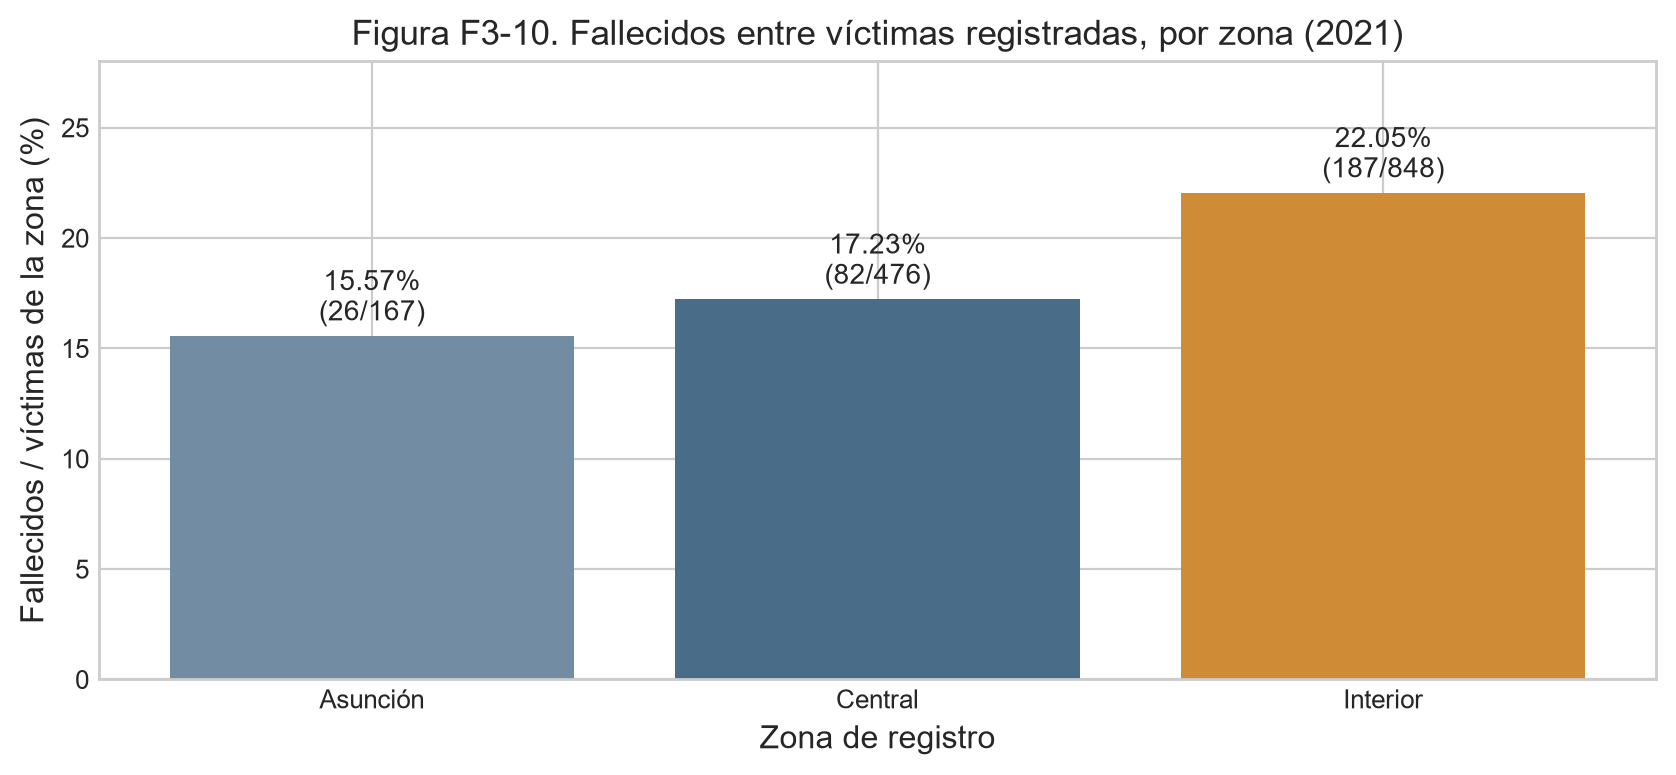

In [8]:
# Contextos separados: no alteran X_demog, particiones, modelos ni métricas.
tablas_contexto, tabla_vehicular, auditoria_contexto = preparar_contexto(Path(BASE_DIR))
territorio = tablas_contexto['territorio']
display(territorio.round(4))
display(Markdown('**Lectura de la tabla:** cada denominador es el total de víctimas de su zona, no población expuesta ni cantidad de accidentes. Heridos + fallecidos coincide con el total.'))
display(tablas_contexto['territorio_h1'].round(4))
display(Markdown('**Agrupación histórica H1:** Metropolitana suma Asunción y Central. Se conserva esa definición para recuperar el contraste de Fase 2; no se interpreta como prueba de todas las diferencias entre las tres zonas.'))
display(tablas_contexto['antecedentes_historicos'].loc[['H1'], ['prueba_aplicada', 'estadístico', 'p_valor_crudo', 'p_valor_ajustado_bonferroni', 'tamaño_del_efecto']])
display(Markdown('**Antecedente:** se informa el p ajustado junto con el efecto. No se recalcula el contraste ni se trasladan sus resultados al problema predictivo demográfico.'))
fig_territorio, ax_territorio = plt.subplots(figsize=(8.5, 4))
barras = ax_territorio.bar(territorio.index, territorio.tasa_fallecidos_pct, color=['#728ca3', '#496d89', '#cf8b36'])
for barra, fila in zip(barras, territorio.itertuples()):
    ax_territorio.text(barra.get_x()+barra.get_width()/2, barra.get_height()+.7,
                      f'{fila.tasa_fallecidos_pct:.2f}%\n({fila.fallecidos}/{fila.total_victimas})', ha='center', fontsize=10)
ax_territorio.set(title='Figura F3-10. Fallecidos entre víctimas registradas, por zona (2021)',
                  xlabel='Zona de registro', ylabel='Fallecidos / víctimas de la zona (%)', ylim=(0, 28))
fig_territorio.tight_layout()
plt.show()


### Interpretación territorial H1
Las fracciones de fallecidos entre víctimas registradas son Asunción 15.57 %, Central 17.23 % e Interior 22.05 %. Metropolitana agrupa Asunción y Central: 108/643 = 16.80 %; Interior la supera en 5.26 puntos porcentuales. H1 de Fase 2 informó χ² = 6.3647 (gl = 1), p crudo 0.011641 y p Bonferroni 0.046565; OR = 1.4014; V de Cramér = 0.0653. El efecto es pequeño y el p ajustado queda cerca de 0,05. La decisión corresponde a esa agrupación y familia de cuatro contrastes, no a todas las comparaciones entre zonas. Mostrar tres tasas revela la heterogeneidad que la dicotomía oculta; no se buscan nuevos p-valores. La cobertura institucional, el registro, la exposición y la atención pueden influir. Son proporciones entre víctimas, no riesgo poblacional de accidente ni un efecto causal de residir en una zona. Las 36 celdas mensuales permiten evaluación binomial cronológica complementaria; no se expanden ni se enlazan con los perfiles demográficos.


### 4.B. H3 — Siniestros protagonizados por motociclistas
**Objetivo:** describir las víctimas de 12.2.10 en 2021 y auditar la procedencia de `victimas_vehiculo_limpio.csv`, conservado como antecedente de Fases 1/2.

**Método y validez:** se leen 12.2.5 y 12.2.10 originales, se selecciona 2021, se comparan los doce meses y se cotejan los conteos expandidos del CSV anterior con las frecuencias oficiales y su resta histórica. No se reinterpreta una coincidencia numérica como validación semántica. El cuadro 12.2.10 describe víctimas de siniestros *protagonizados por motociclistas*: no identifica necesariamente el vehículo de cada víctima ni acredita explícitamente su relación de subconjunto con 12.2.5. Por ello no procede un segundo modelo por tipo de usuario.

Se mantiene el contraste de H3 como antecedente condicionado. Sus RR, OR y valores p no constituyen una demostración de riesgo individual de viajar en motocicleta. Fuentes: [anuario oficial, páginas 307 y 311](https://www.ine.gov.py/Publicaciones/Biblioteca/documento/240/Anuario%20Estadistico%202021.pdf).


,grupo,heridos,fallecidos,fraccion_fallecidos
0,12.2.10: siniestros con motociclistas,384,155,0.2876
1,12.2.5: total de su cobertura,1055,269,0.2032
2,Resta histórica (cobertura no demostrada),671,114,0.1452


**Lectura documental:** las primeras dos filas son coberturas potencialmente superpuestas; la tercera es una resta condicionada, no una categoría oficial de otros vehículos. Las fracciones usan el total de víctimas de cada fila.

,heridos,fallecidos,total,origen
tipo_usuario,,,,
Motociclista,384,155,539,Conteos de 12.2.10; rol de víctima no acreditado
Otro Vehiculo,671,114,785,Resta 12.2.5 menos 12.2.10; categoría no acred...


**Procedencia del CSV histórico:** las etiquetas Motociclista y Otro Vehiculo reproducen la construcción de Fase 1, pero sus nombres no quedan acreditados por las tablas oficiales. Verificar sus conteos no valida esas etiquetas.

,mes,heridos_12_2_5,fallecidos_12_2_5,heridos_12_2_10,fallecidos_12_2_10,heridos_resta,fallecidos_resta
0,Enero,64,14,20,4,44,10
1,Febrero,77,20,20,13,57,7
2,Marzo,71,14,24,11,47,3
3,Abril,84,17,34,11,50,6
4,Mayo,117,29,40,16,77,13
5,Junio,89,27,22,13,67,14
6,Julio,87,27,35,20,52,7
7,Agosto,84,27,38,21,46,6
8,Setiembre,93,26,41,13,52,13
9,Octubre,84,26,35,16,49,10


**Cotejo mensual:** los totales de los doce meses coinciden con los anuales y todos los residuos son no negativos. Son condiciones aritméticas necesarias, insuficientes para demostrar universos y definiciones equivalentes.

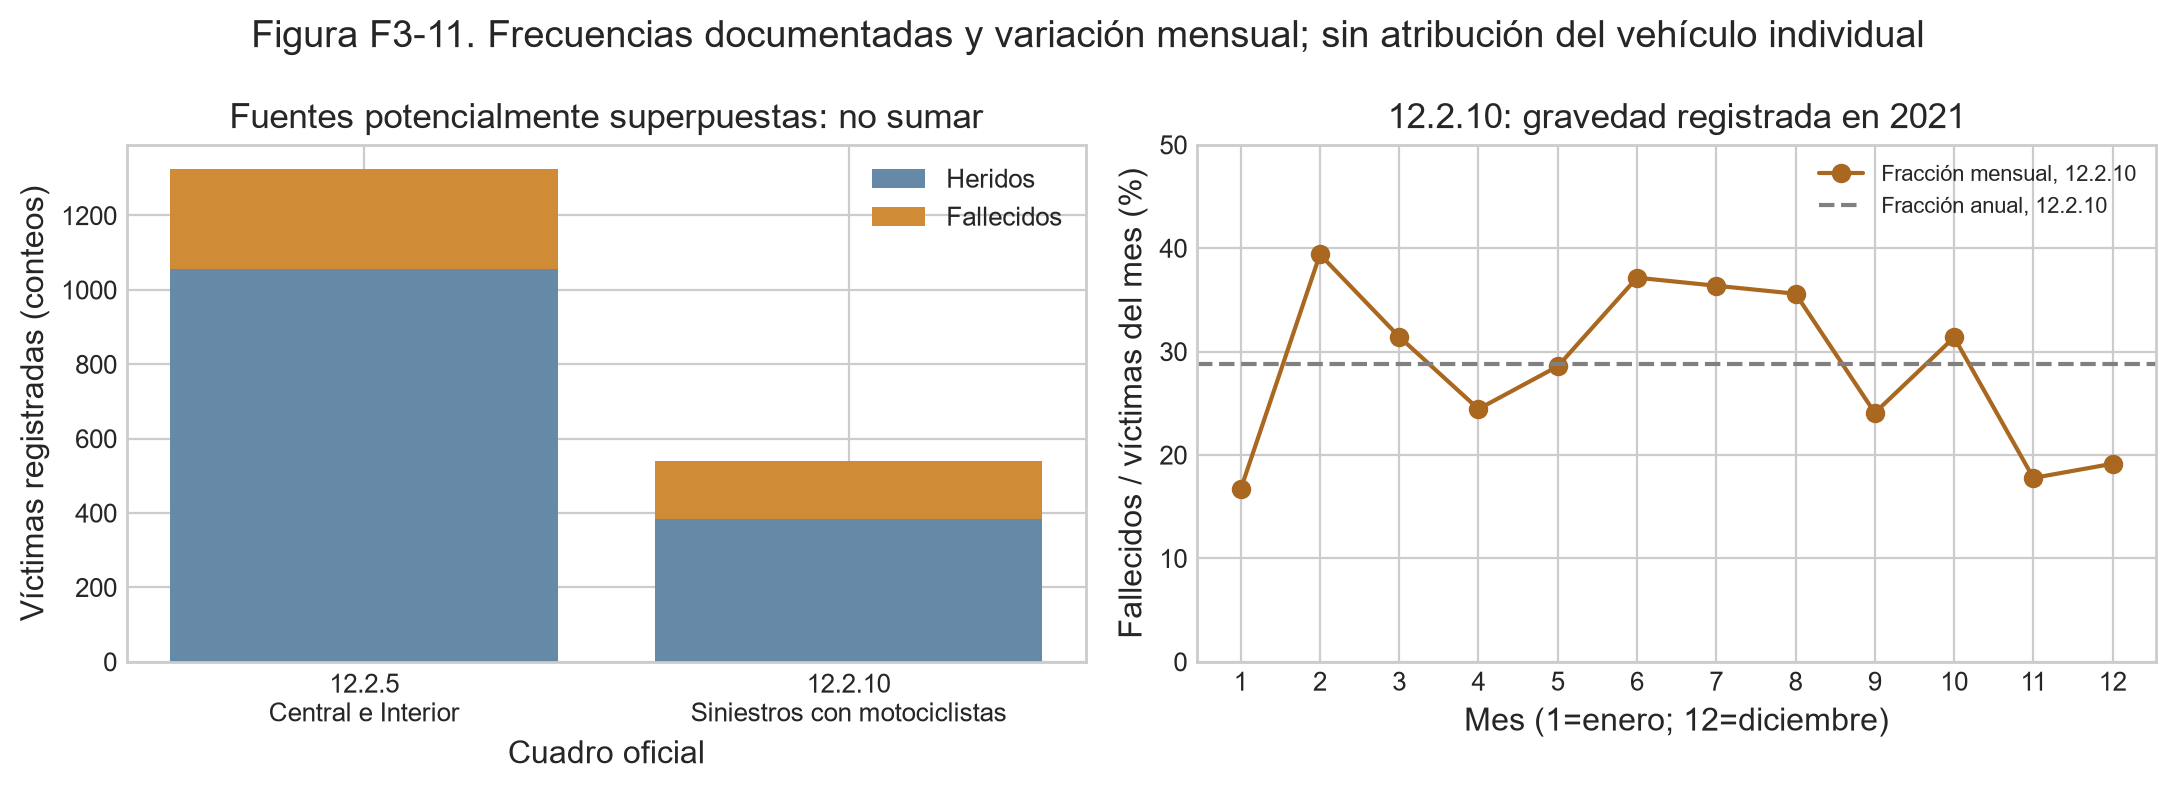

In [9]:
display(tabla_vehicular.round(4))
display(Markdown('**Lectura documental:** las primeras dos filas son coberturas potencialmente superpuestas; la tercera es una resta condicionada, no una categoría oficial de otros vehículos. Las fracciones usan el total de víctimas de cada fila.'))
display(tablas_contexto['vehicular_procedencia'])
display(Markdown('**Procedencia del CSV histórico:** las etiquetas Motociclista y Otro Vehiculo reproducen la construcción de Fase 1, pero sus nombres no quedan acreditados por las tablas oficiales. Verificar sus conteos no valida esas etiquetas.'))
mensual_vehicular = tablas_contexto['vehicular_mensual']
display(mensual_vehicular)
display(Markdown('**Cotejo mensual:** los totales de los doce meses coinciden con los anuales y todos los residuos son no negativos. Son condiciones aritméticas necesarias, insuficientes para demostrar universos y definiciones equivalentes.'))
fig_vehicular, axes_vehicular = plt.subplots(1, 2, figsize=(11, 4))
fuentes = tabla_vehicular.iloc[[1, 0]]
etiquetas = ['12.2.5\nCentral e Interior', '12.2.10\nSiniestros con motociclistas']
axes_vehicular[0].bar(etiquetas, fuentes.heridos, label='Heridos', color='#6689a7')
axes_vehicular[0].bar(etiquetas, fuentes.fallecidos, bottom=fuentes.heridos, label='Fallecidos', color='#cf8b36')
axes_vehicular[0].set(title='Fuentes potencialmente superpuestas: no sumar', ylabel='Víctimas registradas (conteos)', xlabel='Cuadro oficial')
axes_vehicular[0].legend()
fraccion_mensual = 100*mensual_vehicular.fallecidos_12_2_10/(mensual_vehicular.heridos_12_2_10+mensual_vehicular.fallecidos_12_2_10)
axes_vehicular[1].plot(np.arange(1, 13), fraccion_mensual, marker='o', color='#a96720', label='Fracción mensual, 12.2.10')
axes_vehicular[1].axhline(100*tabla_vehicular.iloc[0].fraccion_fallecidos, ls='--', color='grey', label='Fracción anual, 12.2.10')
axes_vehicular[1].set(title='12.2.10: gravedad registrada en 2021', xlabel='Mes (1=enero; 12=diciembre)', ylabel='Fallecidos / víctimas del mes (%)', xticks=range(1, 13), ylim=(0, 50))
axes_vehicular[1].legend(fontsize=8)
fig_vehicular.suptitle('Figura F3-11. Frecuencias documentadas y variación mensual; sin atribución del vehículo individual')
fig_vehicular.tight_layout()
plt.show()
prob_demog_opt = mejor_modelo_demografico.predict_proba(X_test_d)[:, 1]


### Interpretación de las fuentes H3
12.2.10 documenta 539 víctimas de siniestros protagonizados por motociclistas: 384 heridos y 155 fallecidos (28.76 %). 12.2.5 registra 1324 víctimas: 1055 heridos y 269 fallecidos (20.32 %) en Central e Interior. Se selecciona 2021 en ambas y se verifican los doce meses. La resta histórica da 671 heridos y 114 fallecidos; es la procedencia numérica del CSV vehicular, no una validación de sus etiquetas. Aunque ambos cuadros citan a Patrulla Caminera y las restas mensuales son no negativas, no se acredita que cada víctima viajara en moto ni que sean subconjuntos de cobertura idéntica. Las barras representan fuentes posiblemente superpuestas y no deben sumarse. La serie mensual describe esa cobertura, sin demostrar estacionalidad ni causas. H3 histórico informó RR = 1.9802; OR = 2.3758 y p Bonferroni 5.085e-10; se conserva como contraste condicionado. Ni RR, OR ni significación acreditan mayor riesgo individual de motociclistas si las categorías no están validadas. No se entrena un segundo predictor ni se unen estas filas expandidas con la base demográfica.


### 5. Análisis de errores del modelo demográfico seleccionado
La matriz de confusión informa aciertos, falsos positivos y falsos negativos en la evaluación final de **1.099 filas expandidas**. Se extraen los **perfiles demográficos** con mayor error de puntuación. Dado que no tenemos registros individuales completos, no podemos conocer velocidades, tipos de lesión, características del choque ni causas concretas de sus errores.


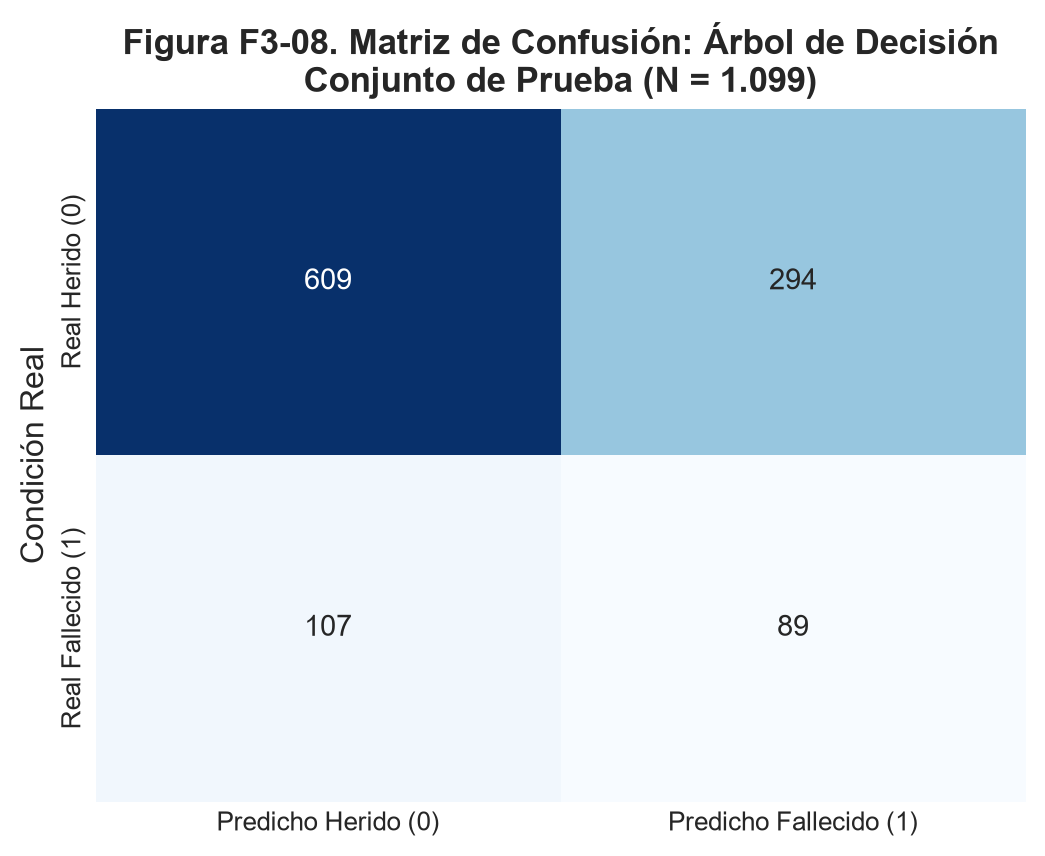

TABLA 4: PERFILES CON MAYOR RESIDUO DE ERROR EN EL CONJUNTO DE PRUEBA


,sexo,grupo_edad,Real,Predicho,Prob_Fallecido,Error_Absoluto,Tipo_Error
4903,Hombre,De 60 anos y mas,0,1,0.7391,0.7391,Falso Positivo (Falsa Alarma)
2876,Mujer,De 18 a 29 anos,1,0,0.2749,0.7251,Falso Negativo (Omisión de Fatalidad)
753,Mujer,De 14 a 17 anos,1,0,0.2822,0.7178,Falso Negativo (Omisión de Fatalidad)
3826,Mujer,De 30 a 39 anos,1,0,0.3457,0.6543,Falso Negativo (Omisión de Fatalidad)
4647,Hombre,De 50 a 59 anos,0,1,0.6541,0.6541,Falso Positivo (Falsa Alarma)
4460,Mujer,De 40 a 49 anos,1,0,0.3721,0.6279,Falso Negativo (Omisión de Fatalidad)
5489,Mujer,Ignorado,1,0,0.3765,0.6235,Falso Negativo (Omisión de Fatalidad)
711,Hombre,De 14 a 17 anos,1,0,0.4075,0.5925,Falso Negativo (Omisión de Fatalidad)


In [10]:
# 1. Matriz de Confusión
pred_opt = mejor_modelo_demografico.predict(X_test_d)
cm = confusion_matrix(y_test_d, pred_opt)

fig_cm, ax_cm = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Predicho Herido (0)', 'Predicho Fallecido (1)'],
            yticklabels=['Real Herido (0)', 'Real Fallecido (1)'])
ax_cm.set_title(f"Figura F3-08. Matriz de Confusión: {nombre_mejor_modelo}\nConjunto de Prueba (N = 1.099)", fontweight='bold')
ax_cm.set_ylabel("Condición Real")

plt.show()

# 2. Extracción sistemática de los casos peor predichos
df_analisis_error = X_test_d.copy()
df_analisis_error['Real'] = y_test_d
df_analisis_error['Predicho'] = pred_opt
df_analisis_error['Prob_Fallecido'] = prob_demog_opt.round(4)
df_analisis_error['Error_Absoluto'] = np.abs(df_analisis_error['Real'] - df_analisis_error['Prob_Fallecido'])

condiciones = [
    (df_analisis_error['Real'] == 1) & (df_analisis_error['Predicho'] == 0),
    (df_analisis_error['Real'] == 0) & (df_analisis_error['Predicho'] == 1)
]
etiquetas = ['Falso Negativo (Omisión de Fatalidad)', 'Falso Positivo (Falsa Alarma)']
df_analisis_error['Tipo_Error'] = np.select(condiciones, etiquetas, default='Acierto')

# Casos con mayor residuo de probabilidad
peores_fallos = (df_analisis_error[df_analisis_error['Tipo_Error'] != 'Acierto']
                 .sort_values(by='Error_Absoluto', ascending=False)
                 .drop_duplicates(subset=['sexo', 'grupo_edad', 'Tipo_Error']))

print("=" * 95)
print("TABLA 4: PERFILES CON MAYOR RESIDUO DE ERROR EN EL CONJUNTO DE PRUEBA")
print("=" * 95)
display(peores_fallos[['sexo', 'grupo_edad', 'Real', 'Predicho', 'Prob_Fallecido', 'Error_Absoluto', 'Tipo_Error']].head(8))

### Interpretación de fallos: conteos y solapamiento verificados
El seleccionado produce **TN=609, TP=89, FP=294 y FN=107** sobre 1.099 filas expandidas. TN/TP son aciertos; FP clasifica una lesión como fatal y FN omite una fatalidad registrada. El FN es prioritario para el objetivo académico, sin convertirlo en un costo clínico ni ajustar umbrales después de mirar test.

El modelo omite **33 de 33 fatalidades entre mujeres** (recall 0.0000); en hombres el recall es 0.5460. También omite las **81 fatalidades de edades de 0 a 29 años**. Los grupos **se superponen**: 15 omisiones son mujeres de esas edades. Su unión es 33 + 81 - 15 = **99**, no su suma directa; los **8 FN restantes** son hombres con edad ignorada. La tabla de descomposición del notebook contiene categorías mutuamente excluyentes y deja la identidad comprobada.

Las mismas combinaciones de sexo y edad reciben la misma predicción: el árbol clasifica herido a todos los perfiles femeninos, jóvenes y de edad ignorada. En los perfiles masculinos de 30 años o más predice fallecido, generando falsas alarmas entre quienes están etiquetados herido; no puede distinguir circunstancias dentro del perfil. Las tasas globales de error y las tasas FN tienen denominadores diferentes. Una tasa global baja puede coexistir con omisión total de fallecidos.

Las filas reconstruyen frecuencias, no historias clínicas identificables. No se conocen velocidad, protección, lesión inicial, tipo de choque ni atención para explicar mecanismos individuales. La ponderación global de clases no garantiza recall equilibrado entre subgrupos. Este patrón impide recomendar aplicaciones individuales y no permite inferir causalidad. La interpretación acotada queda pendiente de revisión por el grupo.

Esta celda se actualiza automáticamente desde las salidas verificadas al ejecutar `src/ejecutar_fase3.py`; no contiene métricas elegidas para mejorar el resultado.


### 6. Coeficientes del modelo logístico e inferencia
Se estiman coeficientes para las variables indicadoras de `sexo` y `grupo_edad`. La exponenciación de los coeficientes es un **odds ratio condicionado por las covariables del modelo**, regularizado y entrenado con ponderación por clase, **no** una razón de riesgo causal ni una nueva prueba de significancia. La categoría de referencia la fija `OneHotEncoder(drop='first')`; hay que identificarla antes de interpretar los signos.


TABLA 5: COEFICIENTES ESTIMADOS POR LA REGRESIÓN LOGÍSTICA DEMOGRÁFICA


,Atributo Codificado,Coeficiente Beta,Odds Ratio (e^Beta)
0,grupo_edad_De 60 anos y mas,1.1296,3.0945
1,grupo_edad_De 50 a 59 anos,0.6549,1.9250
2,grupo_edad_De 40 a 49 anos,0.3825,1.4660
3,grupo_edad_De 30 a 39 anos,0.2376,1.2682
4,grupo_edad_Ignorado,0.1386,1.1486
5,grupo_edad_De 18 a 29 anos,-0.0165,0.9837
6,grupo_edad_De 14 a 17 anos,-0.2703,0.7631
7,sexo_Mujer,-0.7932,0.4524


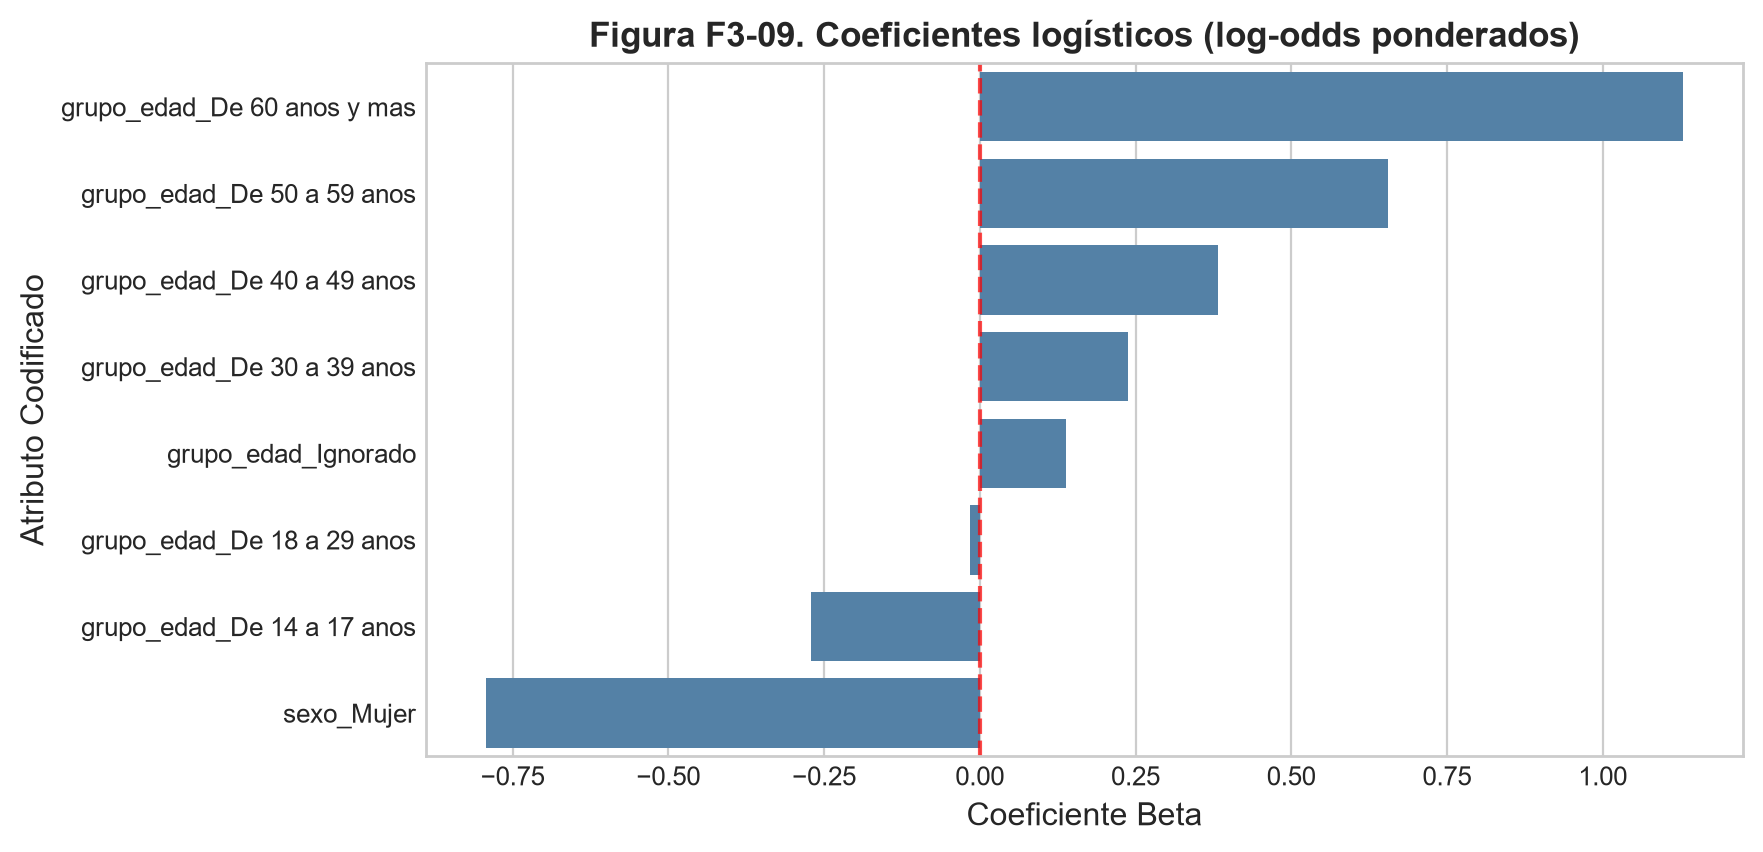

Referencias del encoder: {'sexo': 'Hombre', 'grupo_edad': 'De 0 a 13 anos'}


In [11]:
# Extracción de coeficientes de la Regresión Logística
pipeline_lr = modelos_optimizados["Regresión Logística"]
codificador_ohe = pipeline_lr.named_steps['prep'].named_transformers_['cat']
nombres_ohe = codificador_ohe.get_feature_names_out(columnas_categoricas).tolist()

coeficientes = pipeline_lr.named_steps['clf'].coef_[0]
odds_ratios = np.exp(coeficientes)

df_coef = pd.DataFrame({
    "Atributo Codificado": nombres_ohe,
    "Coeficiente Beta": coeficientes,
    "Odds Ratio (e^Beta)": odds_ratios
}).sort_values(by="Coeficiente Beta", ascending=False).reset_index(drop=True)

print("=" * 80)
print("TABLA 5: COEFICIENTES ESTIMADOS POR LA REGRESIÓN LOGÍSTICA DEMOGRÁFICA")
print("=" * 80)
display(df_coef.round(4))

# Visualización
fig_coef, ax_coef = plt.subplots(figsize=(8.5, 4.5))
sns.barplot(data=df_coef, x="Coeficiente Beta", y="Atributo Codificado", color="steelblue", ax=ax_coef)
ax_coef.axvline(0, color='red', linestyle='--', alpha=0.7)
ax_coef.set_title("Figura F3-09. Coeficientes logísticos (log-odds ponderados)", fontweight='bold')
ax_coef.set_xlabel("Coeficiente Beta")

plt.show()
print('Referencias del encoder:', dict(zip(columnas_categoricas, [c[0] for c in codificador_ohe.categories_])))

### 7. Serialización y trazabilidad
Se conserva el nombre `output/fase3/mejor_modelo_fase3.joblib` para compatibilidad con sus metadatos integrados. Los cuatro candidatos permanecen evaluados en memoria y sus tablas en el notebook. Ningún modelo se reentrena con la prueba. El CLI carga el pipeline desde disco, valida las categorías y devuelve una puntuación no calibrada. Los artefactos vehiculares históricos no se utilizan como productos válidos de esta fase.


In [12]:
# Único artefacto persistente de modelado: pipeline ganador y sus metadatos.
categorias = {c: sorted(X_train_d[c].unique().tolist()) for c in columnas_categoricas}
metadatos = {'modelo': nombre_mejor_modelo, 'variables': columnas_categoricas,
             'categorias': categorias, 'puntuacion': 'no calibrada', 'semilla': RANDOM_STATE,
             'python_entrenamiento': sys.version,
             'sklearn_entrenamiento': __import__('sklearn').__version__,
             'sha256_fuente': auditoria_fuente['sha256_fuente'],
             'validacion': 'CV estratificada interna; test histórico inspeccionado; 16 perfiles repetidos'}
mejor_modelo_demografico.metadatos_fase3_ = metadatos
ruta_modelo = Path(OUTPUT_DIR) / 'fase3' / 'mejor_modelo_fase3.joblib'
ruta_modelo.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(mejor_modelo_demografico, ruta_modelo)
import importlib.metadata as metadata
versiones = {p: metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'scipy', 'matplotlib', 'joblib', 'nbclient', 'nbformat', 'nbconvert', 'ipykernel']}
versiones['python'] = sys.version
modelo_cargado = joblib.load(ruta_modelo)
assert np.array_equal(modelo_cargado.predict(X_test_d), mejor_modelo_demografico.predict(X_test_d))
print('Pipeline ganador y metadatos integrados: serialización y recarga verificadas.')


Pipeline ganador y metadatos integrados: serialización y recarga verificadas.


## 8. Comparación completa, errores e interpretabilidad
Se muestran matrices, ROC, Precision-Recall y métricas de todos los candidatos, incluido Dummy, sobre la misma reserva. Los errores se agrupan por sexo, edad y perfil completo; se distinguen números absolutos y tasas con su denominador. Un falso negativo omite una fatalidad registrada y es prioritario para el objetivo académico, sin definir una política clínica.

La importancia Gini cuantifica reducción de impureza y se suma por variable original. La permutación mide caída de F1 al desordenar cada columna completa; sus desvíos reflejan solo la aleatoriedad de permutar. Con dos variables y perfiles repetidos, no representan certeza causal ni incertidumbre poblacional. La calibración se diagnostica sin ajustar un calibrador en test.

Se verifica además la equivalencia del modelo logístico entre filas expandidas y frecuencias por clase/perfil con pesos. Finalmente se aplica GroupKFold a todos los candidatos con hiperparámetros fijos: extrapolar a combinaciones ausentes es más difícil y sigue siendo sensibilidad interna, no validación externa.


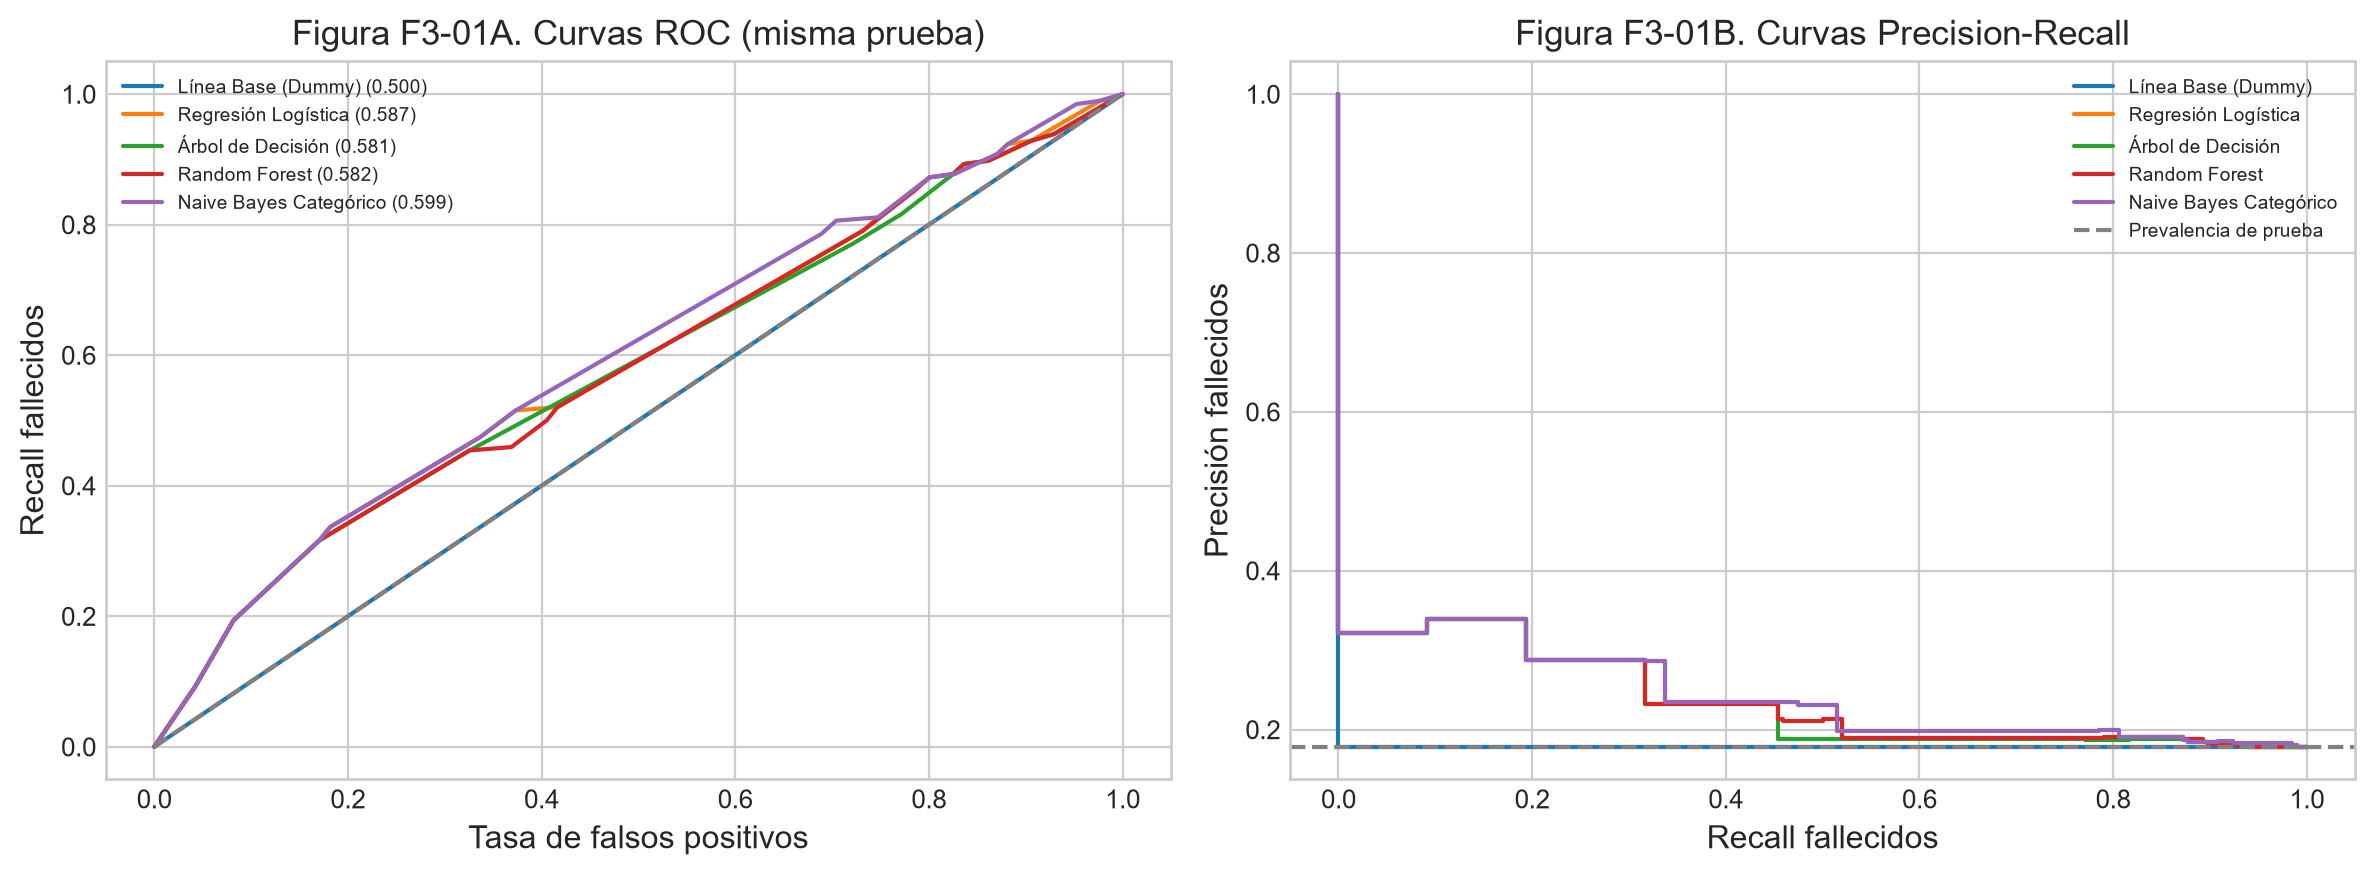

**Interpretación:** Las curvas comparan los mismos 1.099 registros expandidos. AUC y Precision-Recall describen discriminación interna; la línea PR corresponde a la prevalencia de esa reserva. La tabla de métricas permite comprobar las diferencias sin atribuir superioridad externa.

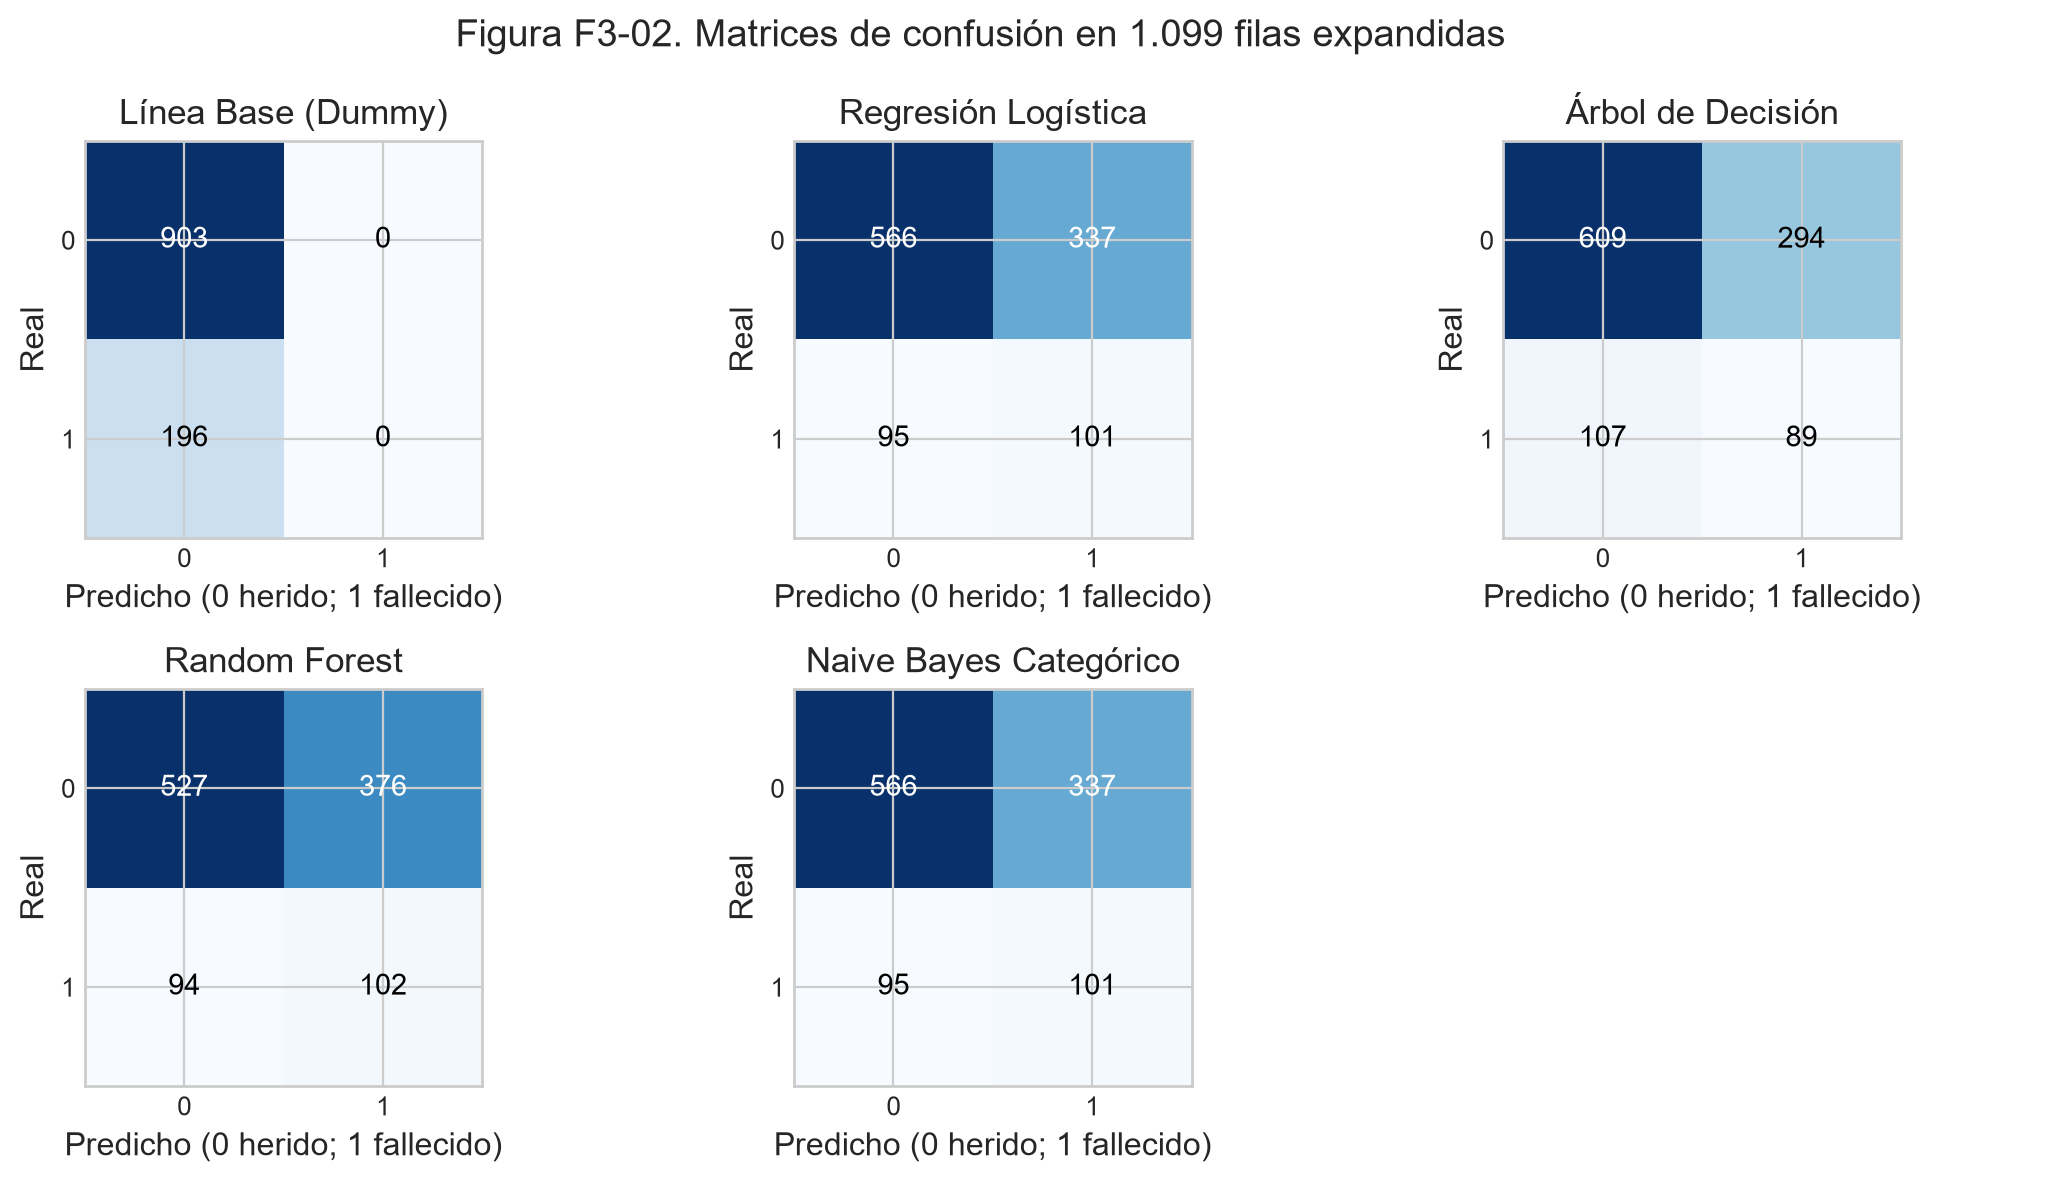

**Interpretación:** Dummy no identifica ninguna fatalidad. Cada matriz permite contrastar omisiones y falsas alarmas con denominadores idénticos; 0 = herido y 1 = fallecido. La diagonal contiene aciertos y las otras celdas errores.

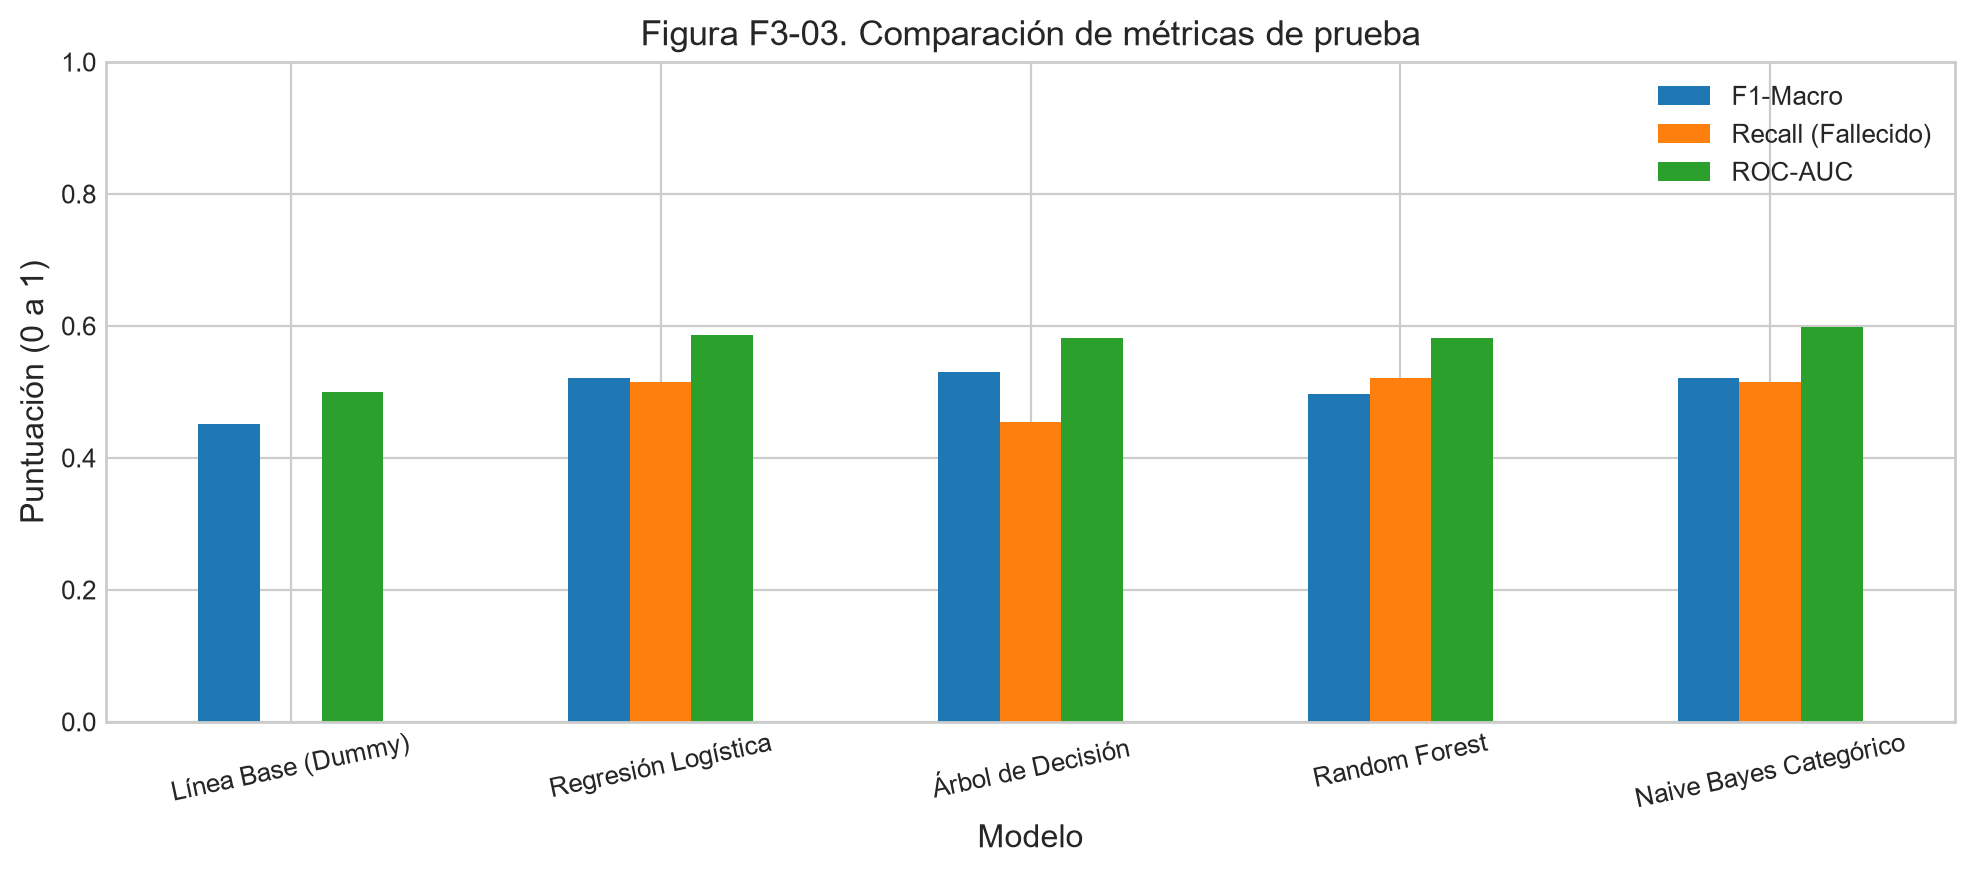

**Interpretación:** El árbol se elige por CV, aunque otro candidato pueda tener AUC de prueba mayor. La mejora de F1 macro frente a Dummy no implica mejor calibración ni una regla clínica.

**Solapamiento de omisiones:** mujeres=33; edades 0-29=81; intersección=15. La unión contiene 99 filas, no la suma directa de ambos grupos. Restan 8 FN de hombres con edad ignorada. Son frecuencias reconstruidas, no expedientes individuales.

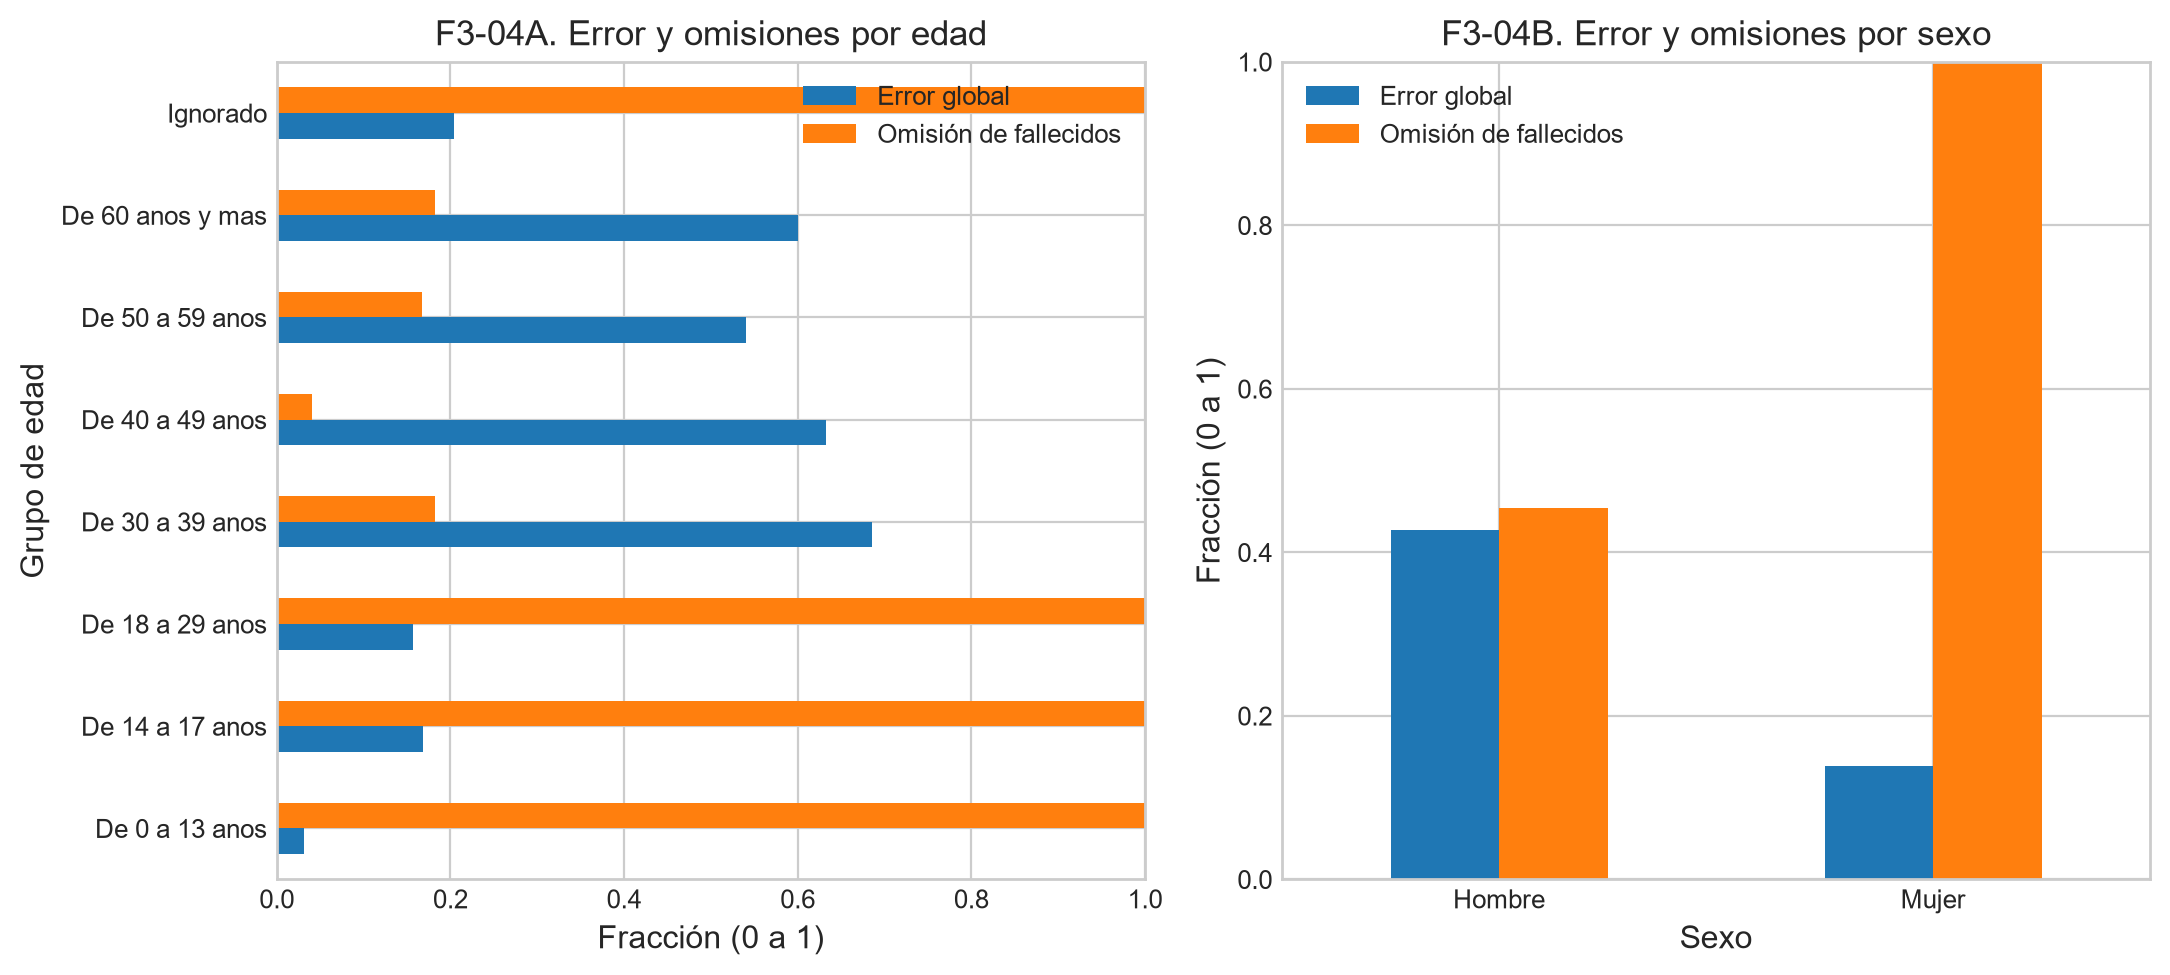

**Interpretación:** La tasa de error divide por todas las filas del grupo; la tasa FN divide solo por sus fallecidos. En particular, el seleccionado no detecta fatalidades entre mujeres de esta reserva y omite las de varios grupos jóvenes. Una tasa global pequeña puede coexistir con omisión total de la clase minoritaria.

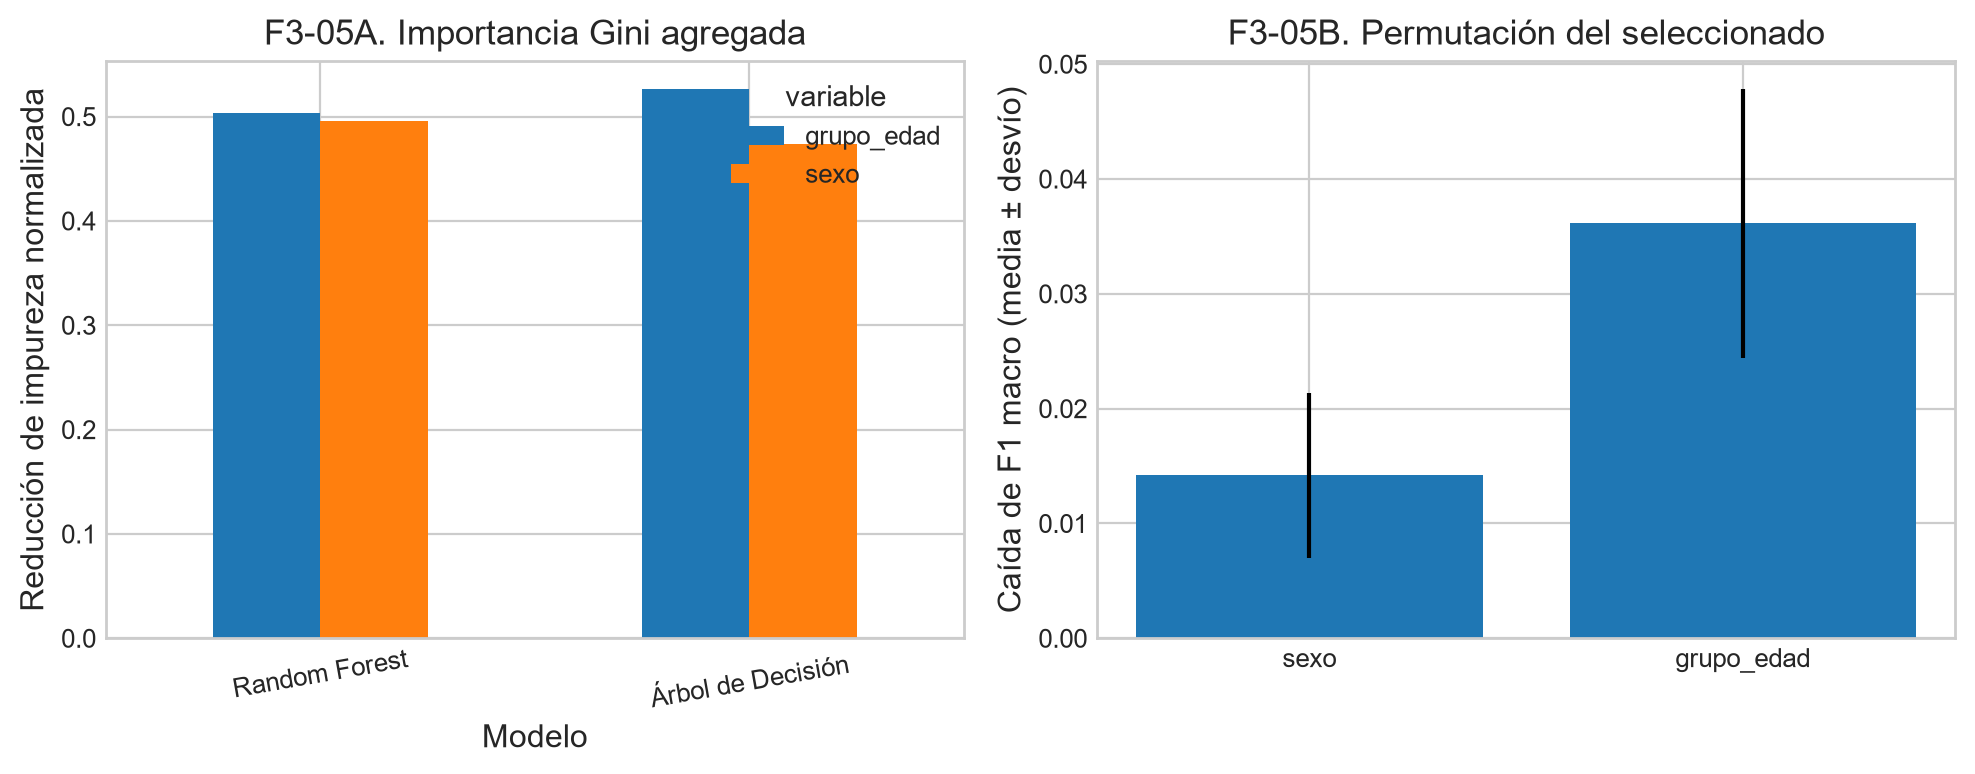

**Interpretación:** Gini agrega la reducción de impureza de los indicadores de cada variable. La permutación mide caída de F1 macro al desordenar la columna completa; sus barras muestran variación entre permutaciones. No representan causalidad ni intervalos poblacionales.

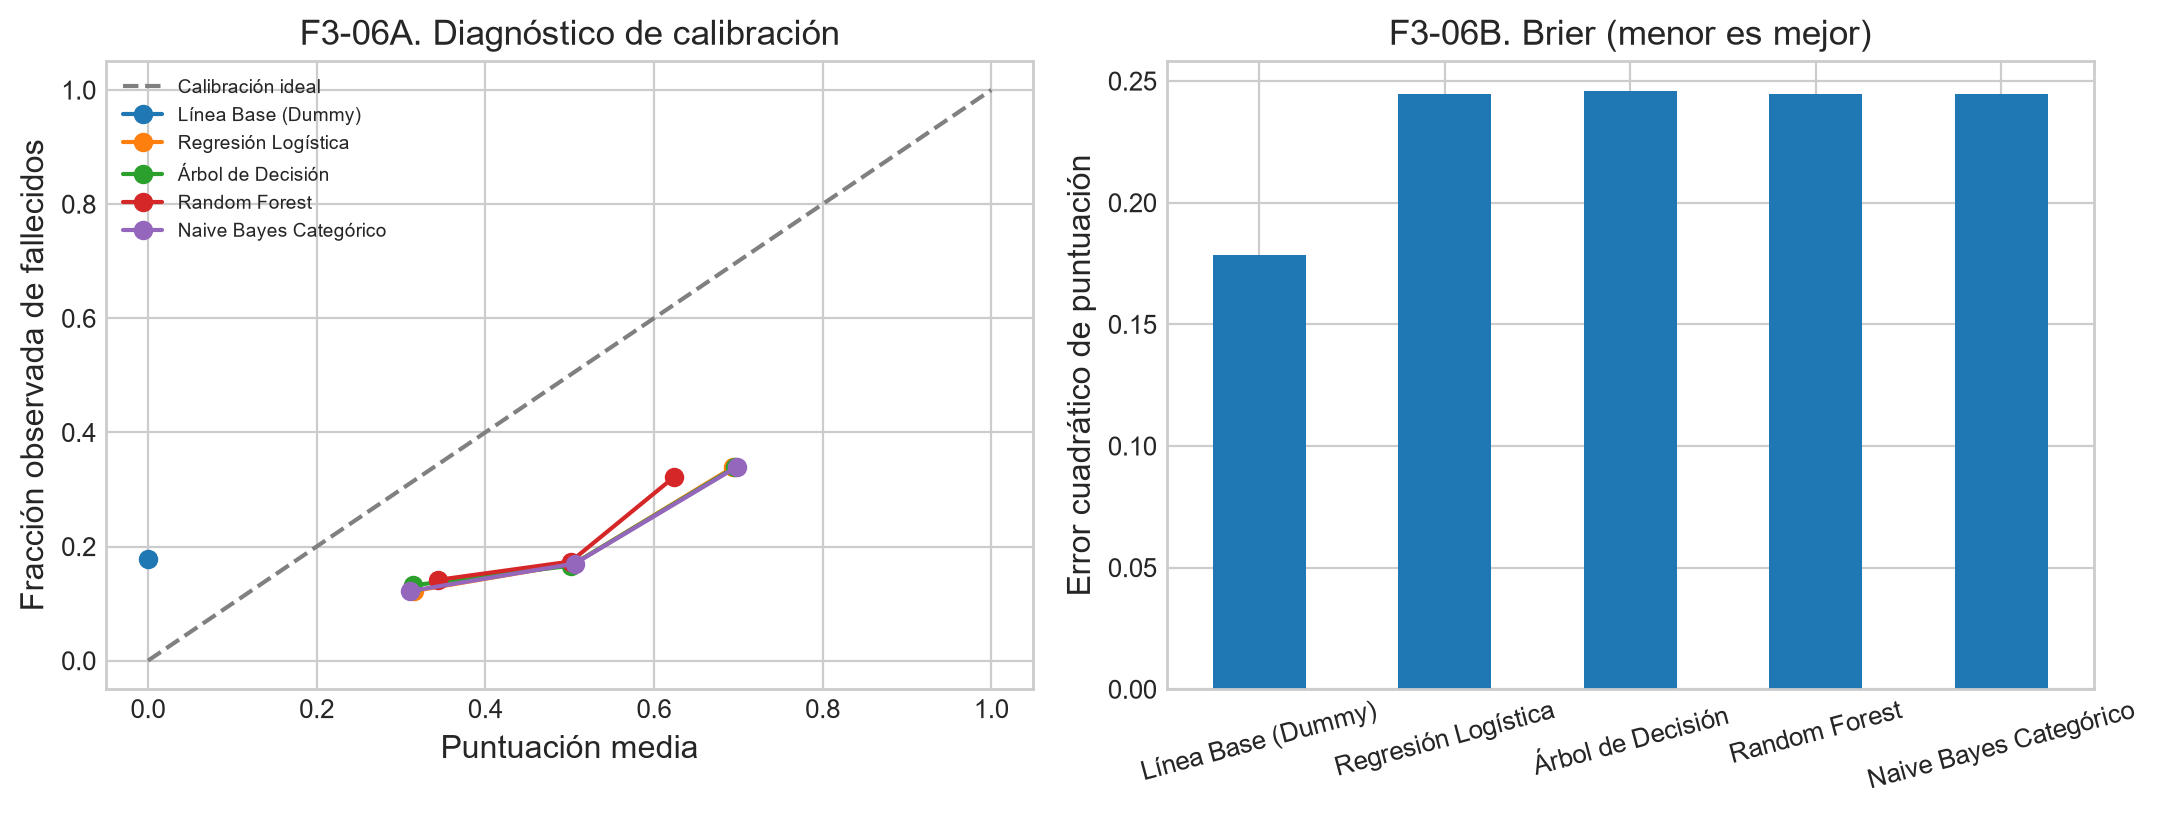

**Interpretación:** La distancia a la diagonal revela discrepancias entre puntuaciones y frecuencia observada. Brier debe compararse con la base, incluso si el modelo mejora F1. No se ajusta calibración en test y no se informa riesgo individual real.

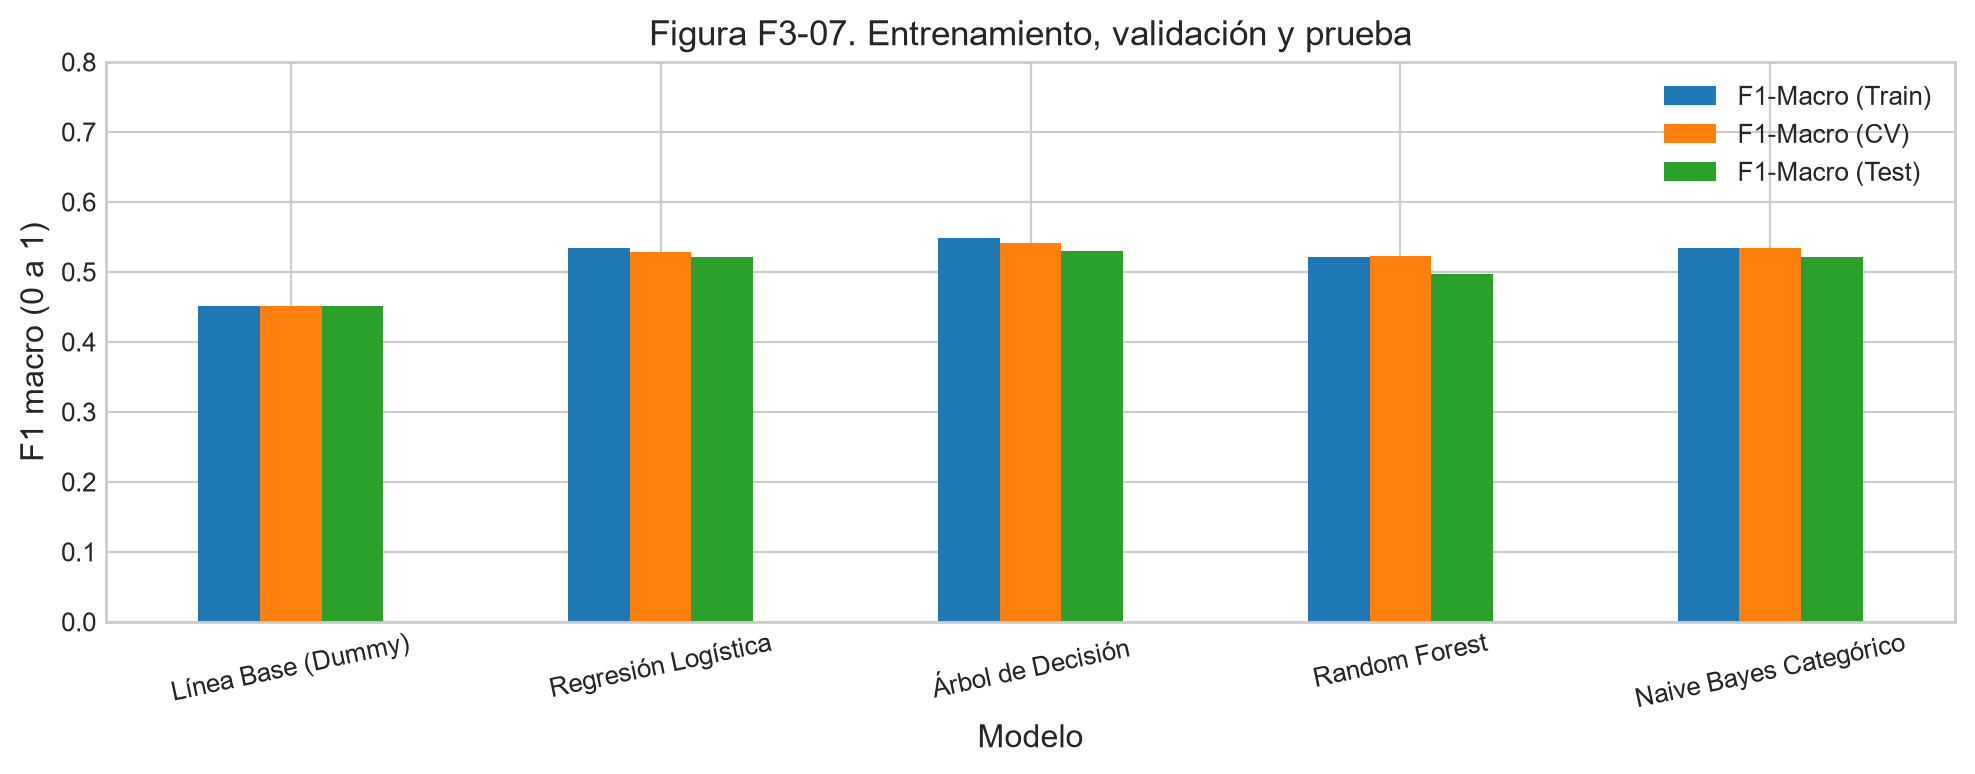

**Interpretación:** Las brechas se cuantifican en las tablas. Su tamaño pequeño está condicionado por perfiles repetidos y por la selección dentro de CV; no acredita generalización externa.

C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preproc

**Tabla: matrices.**

,TN,FP,FN,TP
Modelo,,,,
Línea Base (Dummy),903,0,196,0
Regresión Logística,566,337,95,101
Árbol de Decisión,609,294,107,89
Random Forest,527,376,94,102
Naive Bayes Categórico,566,337,95,101


**Interpretación:** TN y TP son aciertos; FN omite una fatalidad y FP clasifica una lesión como fallecido. Se comparan todos los candidatos sobre la misma reserva.

...

,F1-Macro (Train),F1-Macro (Test),Brecha Absoluta,ROC-AUC (Test),F1-Macro (CV)
Modelo,,,,,
Línea Base (Dummy),0.4510,0.4510,-0.0000,0.5000,0.4510
Regresión Logística,0.5341,0.5212,0.0129,0.5869,0.5278
Árbol de Decisión,0.5490,0.5299,0.0191,0.5809,0.5416
Random Forest,0.5219,0.4971,0.0247,0.5816,0.5234
Naive Bayes Categórico,0.5341,0.5212,0.0129,0.5989,0.5347


**Interpretación:** Train, CV y test muestran una brecha pequeña condicionada por repetición de perfiles, no una garantía de generalización.

**Tabla: sensibilidad todos.**

,Modelo,pliegue,F1_macro,AUC_ROC,n_validacion,perfiles_validacion
0,Línea Base (Dummy),1,0.4536,0.5000,1361,1
1,Regresión Logística,1,0.4536,0.5000,1361,1
2,Árbol de Decisión,1,0.4536,0.5000,1361,1
3,Random Forest,1,0.4536,0.5000,1361,1
4,Naive Bayes Categórico,1,0.4536,0.5000,1361,1
5,Línea Base (Dummy),2,0.4505,0.5000,1000,4
6,Regresión Logística,2,0.3270,0.5446,1000,4
7,Árbol de Decisión,2,0.4449,0.4451,1000,4
8,Random Forest,2,0.4999,0.5446,1000,4
9,Naive Bayes Categórico,2,0.4505,0.5446,1000,4


**Interpretación:** Cada pliegue deja perfiles completos fuera de train, con parámetros ya seleccionados. Es sensibilidad interna y no CV anidada ni validación externa.

In [13]:
tablas_extra = mostrar_complementos(globals())
lecturas = {
    'matrices': 'TN y TP son aciertos; FN omite una fatalidad y FP clasifica una lesión como fallecido. Se comparan todos los candidatos sobre la misma reserva.',
    'descomposicion_FN': 'Las filas son categorías mutuamente excluyentes: separan edad ignorada y evitan contar dos veces mujeres jóvenes. La suma coincide con los 107 FN.',
    'errores_perfil': 'Cada fila representa un perfil repetido, no una historia individual. El residuo medio compara desenlace binario con puntuación no calibrada.',
    'errores_sexo': 'La tasa de error divide por todas las víctimas del sexo; recall y tasa FN dividen por sus fallecidos. Las mujeres presentan 33 omisiones de 33 fatalidades.',
    'errores_edad': 'Ignorado aparece como categoría separada. La omisión de fallecidos no equivale a error entre todas las víctimas del tramo.',
    'gini_indicadores': 'La importancia no tiene signo y distribuye la reducción de impureza entre indicadores; no estima efectos causales.',
    'gini_variables': 'Sumar indicadores permite comparar sexo y grupo_edad en cada árbol, sin equiparar importancia con significación estadística.',
    'permutacion': 'Media: caída de F1 macro al desordenar una variable. Desvío: variación de 30 permutaciones; no es un intervalo poblacional.',
    'calibracion': 'Se contrastan puntuación media y frecuencia observada por intervalo; intervalos vacíos no se reportan. No se ajusta calibración con test.',
    'comparacion_etapas': 'Train, CV y test muestran una brecha pequeña condicionada por repetición de perfiles, no una garantía de generalización.',
    'sensibilidad_todos': 'Cada pliegue deja perfiles completos fuera de train, con parámetros ya seleccionados. Es sensibilidad interna y no CV anidada ni validación externa.'}
for nombre, tabla in tablas_extra.items():
    display(Markdown('**Tabla: ' + nombre.replace('_', ' ') + '.**'))
    display(tabla.round(4))
    display(Markdown('**Interpretación:** ' + lecturas[nombre]))


### 8.B. Integración de H1, H2, H3 y H4
La pregunta original contiene cuatro dimensiones; no exige construir cuatro predictores ni mezclar tablas sin claves de vinculación. Se distingue evidencia descriptiva, inferencia histórica y clasificación retrospectiva. Los antecedentes de H3/H4 conservan sus limitaciones; los resultados anteriores no se borran ni se presentan como pruebas nuevas.


In [14]:
display(tablas_contexto['hipotesis_integradas'])
display(Markdown('**Lectura integrada:** solo H2 y las categorías de H4 entran en el predictor. H1 permanece territorial y H3 documental/condicionado; no hay una estimación conjunta por víctima.'))
display(tablas_contexto['edad_auditoria'])
display(Markdown('**Denominadores de edad:** los tres grupos no se superponen y suman 5.493. Nunca se define menor de 60 únicamente mediante es_adulto_mayor == 0.'))


,factor,fuente,evidencia,limite
hipotesis,,,,
H1,Zona,12.2.6,Tasas y contraste histórico territorial,Cobertura y agrupación; no vínculo individual
H2,Sexo,12.2.1,Asociación histórica y predictor demográfico,Señal limitada; no causa ni riesgo individual
H3,Motocicletas,12.2.5 / 12.2.10,Descripción y contraste histórico condicionado,Rol de víctima y subconjunto no acreditados
H4,Edad,12.2.1,Ordinal corregido y contraste de 60 años; pred...,Inferencia condicional a frecuencias; 353 desc...


**Lectura integrada:** solo H2 y las categorías de H4 entran en el predictor. H1 permanece territorial y H3 documental/condicionado; no hay una estimación conjunta por víctima.

,victimas,heridos,fallecidos
grupo,,,
"Menor de 60, edad conocida",4832,4019,813
60 años o más,308,202,106
Edad desconocida,353,292,61


**Denominadores de edad:** los tres grupos no se superponen y suman 5.493. Nunca se define menor de 60 únicamente mediante es_adulto_mayor == 0.

### H4 y edad desconocida: alcance del antecedente
H4 corregida: solo 5.140 víctimas con edad conocida; 353 desconocidos se mantienen en el dataset nacional. Mann-Whitney unilateral: U=2299236.0, p=1.65678e-20, r de Rosenthal=0.1284; r biserial=0.1854, IC 95% bootstrap=[0.1454667952532276, 0.2266236373446514]. El antecedente conservó -1; la corrección mantiene el rechazo con Bonferroni de cuatro pruebas. Comparación separada de 60 o más frente a menores: RR=2.0455, IC 95%=[1.7318616723664073, 2.4158493942177004], p Fisher unilateral=4.80899e-13. Los dos indicadores de edad desconocida son NA, no cero ni -1. Los intervalos asumen muestreo independiente condicionado a las frecuencias; la fuente no permite verificar conglomeración por siniestro. Edad ordinal no es edad en años; Mann-Whitney contrasta ordenamiento de distribuciones y no solo medianas.


### Respuesta integrada a la pregunta original
H1 aporta diferencias territoriales descriptivas y un contraste histórico de efecto pequeño, condicionado por agrupación y cobertura. H2 aporta una asociación por sexo y H4 patrones por categorías de edad, incorporadas como los únicos predictores del experimento demográfico; H4 se recalculó excluyendo desconocidos del contraste. H3 aporta conteos de siniestros con motociclistas y un contraste anterior condicionado a categorías no acreditadas. Se responde parcialmente la pregunta original: existe señal demográfica retrospectiva limitada y evidencia territorial separada; no se acredita un riesgo individual por vehículo ni el efecto conjunto de los cuatro factores. No se predice ocurrencia de siniestros, no se vinculan artificialmente registros y no se afirma causalidad.


## 9. Discusión, limitaciones y conclusiones académicas
Las conclusiones numéricas siguientes se generan en esta ejecución y quedan pendientes de revisión por el grupo. No se dispone de una devolución docente para contrastar estas correcciones.

H4 se recalcula con 5.140 edades conocidas y se contrasta por separado el grupo de 60 años o más. Las tablas muestran el antecedente con -1, su corrección y los intervalos. Los notebooks históricos de Fase 1 y 2 se conservan como antecedente: no deben usarse para sobrescribir el dataset corregido; la regeneración vigente se hace con `src/regenerar_contexto.py`.

H3 no tiene categorías acreditadas para modelado vehicular. El modelo territorial agregado tiene validación cronológica interna, pero no supera consistentemente a su base; su evaluación no demuestra utilidad futura. Solo el clasificador demográfico se serializa como experimento principal.

### Correcciones inferenciales H4 y modelo territorial agregado
Los contrastes nuevos se registran separados del histórico de Fase 2. La familia conservadora de cuatro pruebas comprende H1, H2, H4 ordinal y el contraste adicional de 60 años; H3 no es acreditable. Los IC son condicionales a conteos: no conocemos dependencia por siniestro ni sesgos de registro. El GLM territorial usa zona y solo meses previos al bloque de validación, sin fabricar víctimas. No supera consistentemente a la base en log-loss/Brier; queda como evaluación exploratoria, sin recomendar su uso predictivo. Sus métricas no son comparables con las del clasificador demográfico.

In [15]:
for clave in ['h4_ordinal', 'h4_mayores60', 'territorio_mensual', 'territorio_validacion', 'territorio_coeficientes']:
    display(Markdown('**' + clave + '**'))
    display(tablas_contexto[clave])
display(Markdown(auditoria_contexto['modelo_territorial']))

**h4_ordinal**

,n_fallecidos,n_heridos,U,p,Z,r_rosenthal,r_biserial,ic95_r_biserial,diferencia_mediana,ic95_diferencia_mediana,bootstrap,semilla,p_bonferroni_4
Histórico con -1,980,4513,2576490.0,2.195670e-17,8.401959,0.113364,0.165110,"[0.12299113219406978, 0.20588974255778097]",1.0,"[0.0, 1.0]",2000,42,8.782681e-17
Corregido edad conocida,919,4221,2299236.0,1.656775e-20,9.208305,0.128439,0.185448,"[0.1454667952532276, 0.2266236373446514]",1.0,"[1.0, 1.0]",2000,42,6.627100e-20


**h4_mayores60**

,fallecidos_mayores,heridos_mayores,fallecidos_menores,heridos_menores,RR,OR,ic95_RR,ic95_OR,p,p_bonferroni_4
0,106,202,813,4019,2.045463,2.594072,"[1.7318616723664073, 2.4158493942177004]","[2.0266255327675, 3.320399982911879]",4.808989e-13,1.923596e-12


**territorio_mensual**

...

**territorio_validacion**

,modelo,ultimo_mes_train,primer_mes_validacion,ultimo_mes_validacion,celdas_train,celdas_validacion,victimas_validacion,log_loss,brier,MAE_proporcion_ponderado
0,Base (tasa global),6,7,8,18,6,254,0.561430,0.185749,0.076868
1,Binomial (zona),6,7,8,18,6,254,0.566999,0.186310,0.074557
2,Base (tasa global),8,9,10,24,6,256,0.532059,0.173673,0.037167
3,Binomial (zona),8,9,10,24,6,256,0.529483,0.172719,0.024324
4,Base (tasa global),10,11,12,30,6,287,0.465254,0.144722,0.035228
5,Binomial (zona),10,11,12,30,6,287,0.468395,0.145725,0.042897


**territorio_coeficientes**

,coeficiente,OR
intercepto,-1.690663,0.184397
Central,0.121032,1.128661
Interior,0.428018,1.534214


36 celdas mes por zona; GLM binomial por zona con conteos [fallecidos, heridos]. Base: tasa global estimada solo con meses anteriores. Cortes 1-6/7-8, 1-8/9-10 y 1-10/11-12. Sin selección por resultados ni predictor de mes; evaluación interna de 2021, sin validación externa. Los denominadores de validación se usan para puntuar tasas, no para ajustar. Dependencia por siniestro, cobertura institucional y variación anual no identificables. No supera consistentemente a la base en log-loss/Brier; se conserva como experimento, sin recomendar su uso predictivo.

In [16]:
sel = df_resultados_test.loc[nombre_mejor_modelo]
base = df_resultados_test.loc['Línea Base (Dummy)']
sens = tablas_extra['sensibilidad_todos'].groupby('Modelo')[['F1_macro', 'AUC_ROC']].mean().loc[nombre_mejor_modelo]
cm = tablas_extra['matrices'].loc[nombre_mejor_modelo]
gini = tablas_extra['gini_variables'].loc['Árbol de Decisión'].sort_values(ascending=False)
por_edad = tablas_extra['errores_edad'].sort_values('tasa_error', ascending=False)
por_sexo = tablas_extra['errores_sexo']
omisiones_mujeres = tablas_extra['errores_sexo'].loc['Mujer']
omisiones_hombres = tablas_extra['errores_sexo'].loc['Hombre']
solapamiento = solapamiento_FN
conclusion = f"""**Resultados reproducidos e interpretación acotada pendiente de revisión por el grupo.** Se seleccionó {nombre_mejor_modelo} por F1 macro CV = {df_reporte_cv.loc[nombre_mejor_modelo, 'F1-Macro (Validación CV)']:.4f}. En prueba interna obtuvo accuracy {sel['Accuracy']:.4f}, precisión {sel['Precision (Fallecido)']:.4f}, recall fallecidos {sel['Recall (Fallecido)']:.4f}, F1 positivo {sel['F1-Score (Fallecido)']:.4f}, F1 macro {sel['F1-Macro']:.4f} y AUC {sel['ROC-AUC']:.4f}. La base obtuvo F1 macro {base['F1-Macro']:.4f}, recall {base['Recall (Fallecido)']:.4f} y AUC {base['ROC-AUC']:.4f}. La diferencia de F1 macro fue {sel['F1-Macro']-base['F1-Macro']:+.4f}. Esto mejora esa métrica dentro del protocolo, sin probar superioridad poblacional.

El seleccionado produjo TN={int(cm.TN)}, FP={int(cm.FP)}, FN={int(cm.FN)} y TP={int(cm.TP)}. FN son fatalidades clasificadas herido; FP son lesiones clasificadas fallecido. La franja con mayor tasa global de error fue {por_edad.index[0]} ({por_edad.iloc[0].tasa_error:.2%}, n={int(por_edad.iloc[0].n)}); debe distinguirse de la tasa de omisión entre fallecidos. Entre mujeres omite {int(omisiones_mujeres.FN)} de {int(omisiones_mujeres.fallecidos)} fatalidades (recall {omisiones_mujeres.recall_fallecidos:.4f}), frente a recall {omisiones_hombres.recall_fallecidos:.4f} entre hombres. Este fallo sistemático impide recomendar el uso individual y no justifica atribuir diferencias a mecanismos biológicos causales. Los grupos se superponen: {solapamiento['interseccion']} omisiones corresponden a mujeres de 0-29 años. La unión es {solapamiento['mujeres']}+{solapamiento['edades_0_29']}-{solapamiento['interseccion']}={solapamiento['union']}, no la suma directa; los {solapamiento['restantes']} FN restantes corresponden a hombres con edad ignorada. Son frecuencias reconstruidas de la reserva, no historias individuales.

La brecha F1 macro train menos test es {df_brechas.loc[nombre_mejor_modelo, 'Brecha Absoluta']:+.4f}; CV train menos validación es {df_reporte_cv.loc[nombre_mejor_modelo, 'Brecha Sobreajuste (CV)']:+.4f}. No basta una brecha pequeña para validar generalización. Dejando perfiles completos fuera, el seleccionado obtiene F1 macro medio {sens.F1_macro:.4f} y AUC medio {sens.AUC_ROC:.4f}. Las categorías ausentes se codifican mediante el manejo explícito del pipeline y su información no puede aprenderse en ese pliegue.

En el árbol, {gini.index[0]} concentra la mayor importancia Gini ({gini.iloc[0]:.4f}). La Fase 2 informó una asociación por sexo (OR 2,0370) y diferencias etarias, pero asociación estadística e importancia predictiva no son equivalentes. Los odds ratios de esta logística están regularizados y ponderados; no son los OR inferenciales históricos. Las categorías de referencia se muestran junto a los coeficientes. No se deduce causalidad.

El Brier del seleccionado es {sel['Brier']:.4f}, frente a {base['Brier']:.4f} de la base. Las curvas F3-06 contrastan puntuación y frecuencia observada; no se realizó calibración ni se convierte el puntaje en probabilidad individual real. La Figura F3-01 compara discriminación y precisión-recall; F3-02 muestra errores absolutos; F3-03 y F3-07 cuantifican las diferencias y brechas. F3-04 identifica grupos de error; F3-05 muestra importancias complementarias; F3-08 detalla la matriz del ganador y F3-09 los coeficientes.

**Respuesta a la pregunta original.** Los conteos de 2021 muestran asociaciones de desenlace con sexo y edad, con capacidad de clasificación retrospectiva limitada. La geografía y los siniestros con motociclistas ofrecen contexto separado; no se puede estimar su efecto conjunto individual. Los resultados no predicen ocurrencia de accidentes, ni autorizan triaje, seguros o vigilancia por perfil. Para mejorar se requieren microdatos vinculados de víctimas y siniestros, vehículo real, casco/cinturón, velocidad, lesiones iniciales, atención y fechas, con control de cobertura y validación en otra población/año. El uso admisible es docente y retrospectivo; se deben revisar sesgos de registro y evitar estigmatización.
"""
conclusion += '\n\n**Integración explícita de las cuatro hipótesis.** ' + auditoria_contexto['conclusion_integral'] + '\n\n' + auditoria_contexto['interpretacion_edad']
display(Markdown(conclusion))

publicar_resultados(globals())


**Resultados reproducidos e interpretación acotada pendiente de revisión por el grupo.** Se seleccionó Árbol de Decisión por F1 macro CV = 0.5416. En prueba interna obtuvo accuracy 0.6351, precisión 0.2324, recall fallecidos 0.4541, F1 positivo 0.3074, F1 macro 0.5299 y AUC 0.5809. La base obtuvo F1 macro 0.4510, recall 0.0000 y AUC 0.5000. La diferencia de F1 macro fue +0.0788. Esto mejora esa métrica dentro del protocolo, sin probar superioridad poblacional.

El seleccionado produjo TN=609, FP=294, FN=107 y TP=89. FN son fatalidades clasificadas herido; FP son lesiones clasificadas fallecido. La franja con mayor tasa global de error fue De 30 a 39 anos (68.54%, n=213); debe distinguirse de la tasa de omisión entre fallecidos. Entre mujeres omite 33 de 33 fatalidades (recall 0.0000), frente a recall 0.5460 entre hombres. Este fallo sistemático impide recomendar el uso individual y no justifica atribuir diferencias a mecanismos biológicos causales. Los grupos se superponen: 15 omisiones corresponden a mujeres de 0-29 años. La unión es 33+81-15=99, no la suma directa; los 8 FN restantes corresponden a hombres con edad ignorada. Son frecuencias reconstruidas de la reserva, no historias individuales.

La brecha F1 macro train menos test es +0.0191; CV train menos validación es +0.0029. No basta una brecha pequeña para validar generalización. Dejando perfiles completos fuera, el seleccionado obtiene F1 macro medio 0.4556 y AUC medio 0.5248. Las categorías ausentes se codifican mediante el manejo explícito del pipeline y su información no puede aprenderse en ese pliegue.

En el árbol, grupo_edad concentra la mayor importancia Gini (0.5267). La Fase 2 informó una asociación por sexo (OR 2,0370) y diferencias etarias, pero asociación estadística e importancia predictiva no son equivalentes. Los odds ratios de esta logística están regularizados y ponderados; no son los OR inferenciales históricos. Las categorías de referencia se muestran junto a los coeficientes. No se deduce causalidad.

El Brier del seleccionado es 0.2457, frente a 0.1783 de la base. Las curvas F3-06 contrastan puntuación y frecuencia observada; no se realizó calibración ni se convierte el puntaje en probabilidad individual real. La Figura F3-01 compara discriminación y precisión-recall; F3-02 muestra errores absolutos; F3-03 y F3-07 cuantifican las diferencias y brechas. F3-04 identifica grupos de error; F3-05 muestra importancias complementarias; F3-08 detalla la matriz del ganador y F3-09 los coeficientes.

**Respuesta a la pregunta original.** Los conteos de 2021 muestran asociaciones de desenlace con sexo y edad, con capacidad de clasificación retrospectiva limitada. La geografía y los siniestros con motociclistas ofrecen contexto separado; no se puede estimar su efecto conjunto individual. Los resultados no predicen ocurrencia de accidentes, ni autorizan triaje, seguros o vigilancia por perfil. Para mejorar se requieren microdatos vinculados de víctimas y siniestros, vehículo real, casco/cinturón, velocidad, lesiones iniciales, atención y fechas, con control de cobertura y validación en otra población/año. El uso admisible es docente y retrospectivo; se deben revisar sesgos de registro y evitar estigmatización.


**Integración explícita de las cuatro hipótesis.** H1 aporta diferencias territoriales descriptivas y un contraste histórico de efecto pequeño, condicionado por agrupación y cobertura. H2 aporta una asociación por sexo y H4 patrones por categorías de edad, incorporadas como los únicos predictores del experimento demográfico; H4 se recalculó excluyendo desconocidos del contraste. H3 aporta conteos de siniestros con motociclistas y un contraste anterior condicionado a categorías no acreditadas. Se responde parcialmente la pregunta original: existe señal demográfica retrospectiva limitada y evidencia territorial separada; no se acredita un riesgo individual por vehículo ni el efecto conjunto de los cuatro factores. No se predice ocurrencia de siniestros, no se vinculan artificialmente registros y no se afirma causalidad.

H4 corregida: solo 5.140 víctimas con edad conocida; 353 desconocidos se mantienen en el dataset nacional. Mann-Whitney unilateral: U=2299236.0, p=1.65678e-20, r de Rosenthal=0.1284; r biserial=0.1854, IC 95% bootstrap=[0.1454667952532276, 0.2266236373446514]. El antecedente conservó -1; la corrección mantiene el rechazo con Bonferroni de cuatro pruebas. Comparación separada de 60 o más frente a menores: RR=2.0455, IC 95%=[1.7318616723664073, 2.4158493942177004], p Fisher unilateral=4.80899e-13. Los dos indicadores de edad desconocida son NA, no cero ni -1. Los intervalos asumen muestreo independiente condicionado a las frecuencias; la fuente no permite verificar conglomeración por siniestro. Edad ordinal no es edad en años; Mann-Whitney contrasta ordenamiento de distribuciones y no solo medianas.

Resultados estructurados embebidos: las tablas, metadatos y conclusiones anteriores permiten regenerar los informes sin archivos intermedios.

## 10. Reproducción y comprobación de la rúbrica
Desde la raíz, crear un entorno Python 3.13.14 e instalar `requirements-lock.txt`. Ejecutar `python src/regenerar_contexto.py` y `python src/ejecutar_fase3.py --verificar`. El runner usa un kernel nuevo, actualiza interpretaciones y exporta HTML; no se deben regenerar documentos durante esta auditoría.

| Apartado | Evidencia | Estado y límites |
|---|---|---|
| 7.1.1–3 | Objetivo binario, pipelines, partición 80/20 semilla 42 | Implementado; frecuencias expandidas, sin fechas individuales |
| 7.1.4–6 | Dummy, cuatro candidatos de tres familias, CV de cinco pliegues y grillas solo en train | Verificado; selección no anidada |
| 7.1.7 | Selección anterior al cálculo de métricas de reserva | Cumplimiento histórico incompleto: test previamente inspeccionado |
| 7.1.8–9 | Matrices, errores, coeficientes, Gini y permutación | Verificado; no explica mecanismos individuales |
| 7.2 | Métricas por clase, F1 macro, AUC, Brier; train/CV/test | Verificado; Brier de CV positivo, menor es mejor |
| 7.3 | Cuatro hipótesis, riesgos, limitaciones y pregunta original | Contenido técnico actualizado; revisión del grupo pendiente |
| 7.4 | Notebook/HTML, joblib e inferencia | Verificado; informes académicos todavía pendientes de revisión |
| 9.3 | Diseño, modelado, errores e interpretación | Evidencias técnicas disponibles; no equivale a aprobación docente |
| 9.5, 10, 12 | Ejecución sin errores, rutas relativas, semillas y pruebas | Verificado para Fase 3; uso único histórico del test no demostrable |

Los documentos de `docs/` se preservan sin cambios. Los hallazgos, correcciones y pendientes están en `AUDITORIA_TECNICA_FASE3.md`. El grupo debe revisar y defender las decisiones y declarar el uso de asistencia conforme a la sección 11 de la consigna.

## Referencias y uso de IA
- INE. Anuario 2021: tablas 12.2.1 y 12.2.2 a 12.2.12 disponibles en el repositorio. [Catálogo oficial](https://www.datos.gov.py/dataset/anuario-2021-estadisticas-policiales-y-de-accidentes-de-transito). Las instituciones generadoras y coberturas difieren.
- Scikit-learn. [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html), [validación cruzada y grupos](https://scikit-learn.org/stable/modules/cross_validation.html), [importancia por permutación](https://scikit-learn.org/stable/modules/permutation_importance.html), [calibración](https://scikit-learn.org/stable/modules/calibration.html). Consulta: 16/10/2026.
- Consigna local: Proyecto_DataScience_Tres_Fases.pdf, apartados 7, 9.3, 9.5, 10, 11 y 12.
- Fases 1 y 2: notebooks y salidas históricas del repositorio; no se reescribieron como parte de esta revisión.

**Uso de IA:** Codex asistió en la auditoría, implementación, depuración, generación de documentación y propuestas de interpretación. El grupo validó el alcance metodológico y la interpretación acotada; debe comprender y revisar personalmente código, resultados e interpretaciones antes de entregar. No se atribuye autoría o validación científica automática a los integrantes. La asistencia empleada excedió una simple corrección de sintaxis; corresponde al grupo revisar su compatibilidad con el artículo 11 y consultar al docente cuando proceda.

- INE. [Anuario Estadístico 2021, PDF original](https://www.ine.gov.py/Publicaciones/Biblioteca/documento/240/Anuario%20Estadistico%202021.pdf), páginas 307 (12.2.5/12.2.6) y 311 (12.2.10). Se cotejaron encabezados, fuentes y frecuencias; no se encontró acreditación del vehículo individual.
